# IE4483 Artificial Intelligence and Data Mining
## Mini Project Option 1 — Sentiment Classification of Product Reviews

Labels: 0 = negative, 1 = positive.


# 1. Environment and Project Setup

This section detects whether the notebook runs on Google Colab or locally (VS Code / Jupyter), mounts Google Drive on Colab only, defines the project folders, imports packages and fixes the random seed.

- **Colab:** put `train.json` and `test.json` in `MyDrive/IE4483_MiniProject/data/raw/`.
- **Local:** put them in `IE4483_MiniProject/data/raw/` next to this notebook (or directly next to the notebook).


In [1]:
import sys

# Check if running on Colab
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
else:
    print("Running locally - Google Drive mount skipped.")

Running locally - Google Drive mount skipped.


In [2]:
import os

if IN_COLAB:
    PROJECT_ROOT = "/content/drive/MyDrive/IE4483_MiniProject"
else:
    PROJECT_ROOT = os.path.join(os.getcwd(), "IE4483_MiniProject")

DATA_RAW_DIR = f"{PROJECT_ROOT}/data/raw"
DATA_PROCESSED_DIR = f"{PROJECT_ROOT}/data/processed"
MODELS_DIR = f"{PROJECT_ROOT}/models"
NOTEBOOK_DIR = f"{PROJECT_ROOT}/notebook"
REFERENCES_DIR = f"{PROJECT_ROOT}/references"

RESULTS_DIR = f"{PROJECT_ROOT}/results"
METRICS_DIR = f"{RESULTS_DIR}/metrics"
FIGURES_DIR = f"{RESULTS_DIR}/figures"
PREDICTIONS_DIR = f"{RESULTS_DIR}/predictions"
ERROR_DIR = f"{RESULTS_DIR}/error_analysis"
EXPERIMENTS_DIR = f"{RESULTS_DIR}/experiments"

SUBMISSIONS_DIR = f"{PROJECT_ROOT}/submissions"

required_dirs = [
    DATA_RAW_DIR, DATA_PROCESSED_DIR, MODELS_DIR, NOTEBOOK_DIR,
    REFERENCES_DIR, RESULTS_DIR, METRICS_DIR, FIGURES_DIR,
    PREDICTIONS_DIR, ERROR_DIR, EXPERIMENTS_DIR, SUBMISSIONS_DIR
]

for folder in required_dirs:
    os.makedirs(folder, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("All project folders are ready.")


Project root: C:\Users\Rafael Bantilan\OneDrive\Desktop\AI DATA\IE4483_MiniProject
All project folders are ready.


In [3]:
import json
import random
import time
import re
import copy
import joblib
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold
)
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_auc_score,
    make_scorer
)

# PyTorch is optional
try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    from torch.utils.data import TensorDataset, DataLoader
    TORCH_AVAILABLE = True
except ImportError:
    torch = None
    TORCH_AVAILABLE = False

if TORCH_AVAILABLE:
    print("PyTorch version:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())

    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
else:
    print("PyTorch not installed - neural-network cells will be skipped.")


# Skip a cell if PyTorch is missing
from IPython import get_ipython
from IPython.core.magic import register_cell_magic


@register_cell_magic
def requires_torch(line, cell):
    if not TORCH_AVAILABLE:
        print("Skipped: PyTorch is not installed in this environment.")
        return

    result = get_ipython().run_cell(cell)
    result.raise_error()


PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 3060 Ti


In [4]:
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)

    if TORCH_AVAILABLE:
        torch.manual_seed(seed)

        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
            torch.backends.cudnn.deterministic = True
            torch.backends.cudnn.benchmark = False

set_seed(SEED)
print(f"Random seed fixed at {SEED}")


Random seed fixed at 42


# 2. Dataset Loading and Exploration

The provided training set contains raw reviews and binary sentiment labels.  
The test set contains reviews only and therefore has no local ground-truth accuracy.


In [5]:
# Look in data/raw, then the notebook folder
for data_dir in [DATA_RAW_DIR, os.getcwd()]:
    if os.path.exists(f"{data_dir}/train.json"):
        break

TRAIN_PATH = f"{data_dir}/train.json"
TEST_PATH = f"{data_dir}/test.json"

assert os.path.exists(TRAIN_PATH), "train.json not found."
assert os.path.exists(TEST_PATH), "test.json not found."

with open(TRAIN_PATH, "r", encoding="utf-8") as f:
    train_data = json.load(f)

with open(TEST_PATH, "r", encoding="utf-8") as f:
    test_data = json.load(f)

df = pd.DataFrame(train_data)
test_df = pd.DataFrame(test_data)

print("Training shape:", df.shape)
print("Test shape:", test_df.shape)
display(df.head())
display(test_df.head())


Training shape: (7401, 2)
Test shape: (1851, 1)


,reviews,sentiments
0,I bought this belt for my daughter in-law for ...,1
1,The size was perfect and so was the color. It...,1
2,"Fits and feels good, esp. for doing a swim rac...",1
3,These socks are absolutely the best. I take pi...,1
4,Thank you so much for the speedy delivery they...,1


,reviews
0,I bought 2 sleepers. sleeper had holes in the...
1,I dare say these are just about the sexiest th...
2,"everything about the transaction (price, deliv..."
3,"Not bad for just a shirt. Very durable, and m..."
4,These are truly wrinkle free and longer than t...


In [6]:
print("Training columns:", df.columns.tolist())
print("Test columns:", test_df.columns.tolist())

assert "reviews" in df.columns
assert "sentiments" in df.columns
assert "reviews" in test_df.columns
assert set(df["sentiments"].unique()).issubset({0, 1})

print("Training label values:", sorted(df["sentiments"].unique()))


Training columns: ['reviews', 'sentiments']
Test columns: ['reviews']
Training label values: [0, 1]


# 3. Exploratory Data Analysis

We inspect dataset size, missing values, class balance, duplicate reviews and review length before model development.


In [7]:
print("Number of training reviews:", len(df))
print("Number of test reviews:", len(test_df))

print("\nMissing values — training:")
print(df.isnull().sum())

print("\nMissing values — test:")
print(test_df.isnull().sum())

print("\nDuplicate training reviews:")
print(df["reviews"].duplicated().sum())

print("\nClass counts:")
print(df["sentiments"].value_counts())

print("\nClass percentages:")
print((df["sentiments"].value_counts(normalize=True) * 100).round(2))


Number of training reviews:

 7401
Number of test reviews: 1851

Missing values — training:
reviews       0
sentiments    0
dtype: int64

Missing values — test:
reviews    0
dtype: int64

Duplicate training reviews:
216

Class counts:
sentiments
1    6319
0    1082
Name: count, dtype: int64

Class percentages:
sentiments
1    85.38
0    14.62
Name: proportion, dtype: float64


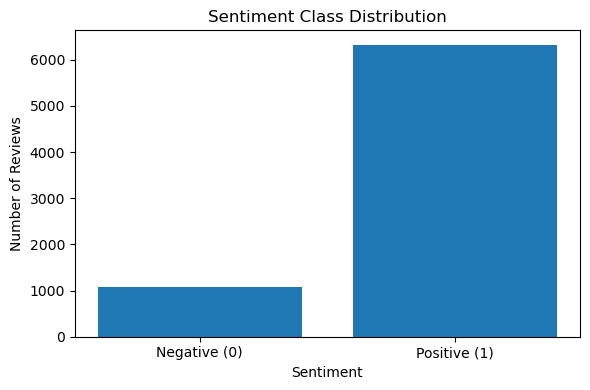

Saved to: C:\Users\Rafael Bantilan\OneDrive\Desktop\AI DATA\IE4483_MiniProject/results/figures/class_distribution.png


In [8]:
class_counts = df["sentiments"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(["Negative (0)", "Positive (1)"], class_counts.values)
plt.title("Sentiment Class Distribution")
plt.ylabel("Number of Reviews")
plt.xlabel("Sentiment")
plt.tight_layout()

figure_path = f"{FIGURES_DIR}/class_distribution.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved to:", figure_path)


count    7401.000000
mean       56.682070
std        53.335842
min         4.000000
25%        25.000000
50%        42.000000
75%        70.000000
max      1066.000000
Name: review_length_words, dtype: float64


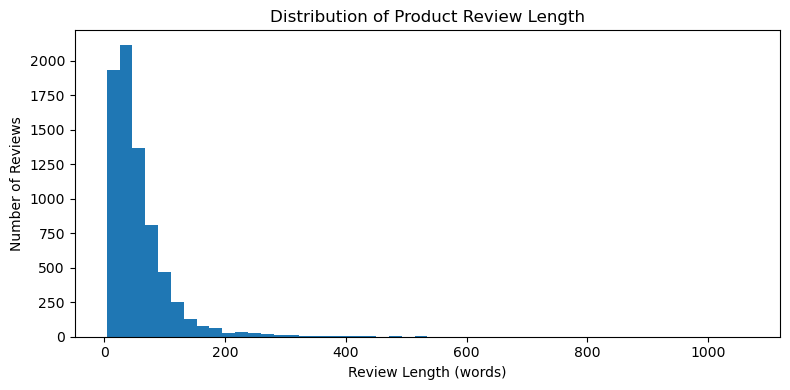

Saved to: C:\Users\Rafael Bantilan\OneDrive\Desktop\AI DATA\IE4483_MiniProject/results/figures/review_length_distribution.png


In [9]:
df["review_length_words"] = df["reviews"].astype(str).str.split().str.len()

print(df["review_length_words"].describe())

plt.figure(figsize=(8, 4))
plt.hist(df["review_length_words"], bins=50)
plt.xlabel("Review Length (words)")
plt.ylabel("Number of Reviews")
plt.title("Distribution of Product Review Length")
plt.tight_layout()

figure_path = f"{FIGURES_DIR}/review_length_distribution.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved to:", figure_path)


# 4. Common Text Preprocessing

The common cleaning step is deliberately conservative:
- convert text to string;
- lowercase;
- collapse repeated whitespace;
- retain meaningful words and negation.

The same cleaned text is used by the classical and neural branches, but the numerical feature representation differs.


In [10]:
def basic_clean_text(text):
    text = str(text).lower()
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["clean_reviews"] = df["reviews"].apply(basic_clean_text)
test_df["clean_reviews"] = test_df["reviews"].apply(basic_clean_text)

display(df[["reviews", "clean_reviews", "sentiments"]].head())


,reviews,clean_reviews,sentiments
0,I bought this belt for my daughter in-law for ...,i bought this belt for my daughter in-law for ...,1
1,The size was perfect and so was the color. It...,the size was perfect and so was the color. it ...,1
2,"Fits and feels good, esp. for doing a swim rac...","fits and feels good, esp. for doing a swim rac...",1
3,These socks are absolutely the best. I take pi...,these socks are absolutely the best. i take pi...,1
4,Thank you so much for the speedy delivery they...,thank you so much for the speedy delivery they...,1


# 5. Common Training and Final Holdout Split

A fixed 80/20 stratified split is used:
- 80% `train_df`: model development and tuning;
- 20% `val_df`: **final holdout comparison only**;
- random seed = 42.

The final `val_df` must not be used to choose n-grams, feature counts, learning rates, CNN architecture or stopping epoch.  
Neural networks may create an **internal tuning split inside `train_df`**. This does not change the common final holdout used for model comparison.


In [11]:
df = df.reset_index(drop=True)
df["row_id"] = np.arange(len(df))

train_df, val_df = train_test_split(
    df,
    test_size=0.20,
    random_state=SEED,
    stratify=df["sentiments"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

y_train = train_df["sentiments"].values
y_val = val_df["sentiments"].values

print("Training samples:", len(train_df))
print("Final holdout samples:", len(val_df))

print("\nTraining label distribution:")
print(train_df["sentiments"].value_counts(normalize=True).sort_index())

print("\nFinal holdout label distribution:")
print(val_df["sentiments"].value_counts(normalize=True).sort_index())


Training samples: 5920
Final holdout samples: 1481

Training label distribution:
sentiments
0    0.146115
1    0.853885
Name: proportion, dtype: float64

Final holdout label distribution:
sentiments
0    0.146523
1    0.853477
Name: proportion, dtype: float64


In [12]:
TRAIN_SPLIT_PATH = f"{DATA_PROCESSED_DIR}/train_split.csv"
VAL_SPLIT_PATH = f"{DATA_PROCESSED_DIR}/val_split.csv"

train_df.to_csv(TRAIN_SPLIT_PATH, index=False)
val_df.to_csv(VAL_SPLIT_PATH, index=False)

print("Saved:")
print(TRAIN_SPLIT_PATH)
print(VAL_SPLIT_PATH)


Saved:
C:\Users\Rafael Bantilan\OneDrive\Desktop\AI DATA\IE4483_MiniProject/data/processed/train_split.csv
C:\Users\Rafael Bantilan\OneDrive\Desktop\AI DATA\IE4483_MiniProject/data/processed/val_split.csv


# 6. Common Evaluation Framework

For the imbalanced dataset, **macro-F1 is the primary tuning/selection metric** because it gives equal importance to both classes.  
Accuracy is still reported, together with positive-class precision/recall/F1, ROC-AUC, confusion matrix and training time.

Final model comparison uses the untouched `val_df`.


In [13]:
def metric_dict(y_true, y_pred, y_score=None):
    result = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Negative Recall": recall_score(
            y_true, y_pred, pos_label=0, zero_division=0
        )
    }

    result["ROC-AUC"] = (
        roc_auc_score(y_true, y_score)
        if y_score is not None
        else np.nan
    )
    return result


def plot_confusion_matrix(y_true, y_pred, model_name, save_name):
    cm = confusion_matrix(y_true, y_pred)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Negative", "Positive"]
    )
    disp.plot()
    plt.title(f"Confusion Matrix — {model_name}")
    plt.tight_layout()

    path = f"{FIGURES_DIR}/{save_name}"
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    print("Saved to:", path)


# 7. TF-IDF + Logistic Regression

## 7.1 Joint training-only search

All Logistic Regression settings are selected together using **5-fold stratified cross-validation inside `train_df` only**:

| Setting | Values |
|---|---|
| n-gram range | (1,1), (1,2), (1,3) |
| TF-IDF `max_features` | 1k, 2k, 5k, 10k, 20k, 40k, all |
| `C` (inverse regularisation) | 0.5, 1, 2, 5, 10, 20, 50, 100 |
| `class_weight` | None, balanced |

**Why one joint search instead of two stages:** the best TF-IDF representation depends on the classifier settings.
Tuning the representation first with an unweighted `C = 1` model and then switching on class weighting picks features
for a different model than the one finally used. In a staged search the unweighted model prefers a small unigram vocabulary,
while the class-weighted model benefits from more features and bigrams. Searching jointly (the same approach as the Linear SVM)
avoids that mismatch.

Primary metric: mean CV macro-F1. The common final holdout `val_df` is not used in this search.


In [14]:
lr_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

lr_scoring = {
    "macro_f1": "f1_macro",
    "accuracy": "accuracy",
    "positive_f1": "f1",
    "negative_recall": make_scorer(
        recall_score,
        pos_label=0,
        zero_division=0
    )
}

lr_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(lowercase=False)),
    ("lr", LogisticRegression(
        solver="lbfgs",
        max_iter=1000,
        random_state=SEED
    ))
])

# None keeps the full vocabulary
lr_param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2), (1, 3)],
    "tfidf__max_features": [1000, 2000, 5000, 10000, 20000, 40000, None],
    "lr__C": [0.5, 1.0, 2.0, 5.0, 10.0, 20.0, 50.0, 100.0],
    "lr__class_weight": [None, "balanced"]
}

lr_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_param_grid,
    scoring=lr_scoring,
    refit="macro_f1",
    cv=lr_cv,
    n_jobs=-1,
    return_train_score=True,
    verbose=0
)

n_lr_configs = int(np.prod([len(v) for v in lr_param_grid.values()]))
print(
    f"Running {n_lr_configs} configurations "
    f"x 5 folds = {n_lr_configs * 5} fits..."
)

start_time = time.time()

lr_search.fit(
    train_df["clean_reviews"],
    y_train
)

lr_search_time = time.time() - start_time

best_ngram_range = lr_search.best_params_["tfidf__ngram_range"]
best_feature_count = lr_search.best_params_["tfidf__max_features"]  # None means the full vocabulary

print(f"Completed in {lr_search_time:.1f} seconds")
print("Best settings by mean CV macro-F1:")
for key, value in lr_search.best_params_.items():
    print(f"  {key}: {value}")
print(f"Best mean CV macro-F1: {lr_search.best_score_:.4f}")


Running 336 configurations x 5 folds = 1680 fits...


Completed in 309.9 seconds
Best settings by mean CV macro-F1:
  lr__C: 20.0
  lr__class_weight: balanced
  tfidf__max_features: 40000
  tfidf__ngram_range: (1, 3)
Best mean CV macro-F1: 0.8389


## 7.2 Search results

The tables below show the best configurations, the best result for each class-weight setting, and how macro-F1 changes with the
TF-IDF feature count when the other selected settings are held fixed. A final check confirms the selected `C` and feature count
are not at the edge of the searched grid.


In [15]:
lr_cv_res = lr_search.cv_results_

lr_results_df = pd.DataFrame({
    "Ngram Range": [str(p["tfidf__ngram_range"]) for p in lr_cv_res["params"]],
    "Max Features": [
        "all" if p["tfidf__max_features"] is None else p["tfidf__max_features"]
        for p in lr_cv_res["params"]
    ],
    "C": [p["lr__C"] for p in lr_cv_res["params"]],
    "Class Weight": [str(p["lr__class_weight"]) for p in lr_cv_res["params"]],
    "CV Macro F1": lr_cv_res["mean_test_macro_f1"],
    "CV Macro F1 Std": lr_cv_res["std_test_macro_f1"],
    "CV Accuracy": lr_cv_res["mean_test_accuracy"],
    "CV Positive F1": lr_cv_res["mean_test_positive_f1"],
    "CV Negative Recall": lr_cv_res["mean_test_negative_recall"],
    "Train Macro F1": lr_cv_res["mean_train_macro_f1"],
    "Mean Fit Time (s)": lr_cv_res["mean_fit_time"]
}).sort_values(
    ["CV Macro F1", "CV Accuracy"],
    ascending=[False, False]
).reset_index(drop=True)

lr_results_path = f"{EXPERIMENTS_DIR}/logistic_regression_joint_cv.csv"
lr_results_df.to_csv(lr_results_path, index=False)

print("Top 15 Logistic Regression configurations (5-fold CV on train_df)")
display(lr_results_df.head(15).round(4))

print("\nBest configuration per class_weight setting:")
display(
    lr_results_df
    .groupby("Class Weight", as_index=False)
    .first()
    .round(4)
)

# Effect of feature count
best_C = lr_search.best_params_["lr__C"]
best_class_weight = str(lr_search.best_params_["lr__class_weight"])

feature_effect_df = lr_results_df[
    (lr_results_df["Ngram Range"] == str(best_ngram_range))
    & (lr_results_df["C"] == best_C)
    & (lr_results_df["Class Weight"] == best_class_weight)
].copy()

feature_order = lr_param_grid["tfidf__max_features"]
feature_effect_df["order"] = feature_effect_df["Max Features"].map(
    lambda v: feature_order.index(None if v == "all" else v)
)

print(
    f"\nEffect of feature count (ngram={best_ngram_range}, "
    f"C={best_C}, class_weight={best_class_weight}):"
)
display(
    feature_effect_df
    .sort_values("order")
    .drop(columns="order")[[
        "Max Features", "CV Macro F1", "CV Macro F1 Std",
        "CV Accuracy", "CV Negative Recall", "Train Macro F1"
    ]]
    .round(4)
)

# Check if the best value is at the edge of the grid
for param in ["lr__C", "tfidf__max_features"]:
    grid_values = lr_param_grid[param]
    best_value = lr_search.best_params_[param]
    if best_value in (grid_values[0], grid_values[-1]) and best_value is not None:
        print(f"NOTE: best {param} = {best_value} is at the edge of the searched grid.")
    else:
        print(f"OK: best {param} = {best_value} is inside the searched grid (or uses the full vocabulary).")

print("\nSaved:", lr_results_path)


Top 15 Logistic Regression configurations (5-fold CV on train_df)


,Ngram Range,Max Features,C,Class Weight,CV Macro F1,CV Macro F1 Std,CV Accuracy,CV Positive F1,CV Negative Recall,Train Macro F1,Mean Fit Time (s)
0,"(1, 3)",40000,20.0,balanced,0.8389,0.0107,0.9226,0.9550,0.6913,0.9992,2.4673
1,"(1, 2)",40000,10.0,balanced,0.8388,0.0110,0.9211,0.9540,0.7075,0.9973,1.2214
2,"(1, 2)",40000,5.0,balanced,0.8387,0.0084,0.9191,0.9526,0.7295,0.9879,1.3821
3,"(1, 3)",10000,50.0,balanced,0.8383,0.0058,0.9209,0.9539,0.7052,0.9999,2.2190
4,"(1, 2)",10000,20.0,balanced,0.8381,0.0109,0.9198,0.9531,0.7179,0.9978,1.1122
5,"(1, 2)",10000,50.0,balanced,0.8373,0.0115,0.9203,0.9535,0.7064,1.0000,1.1050
6,"(1, 2)",20000,5.0,balanced,0.8370,0.0077,0.9179,0.9518,0.7306,0.9811,1.1924
7,"(1, 2)",10000,10.0,balanced,0.8370,0.0079,0.9181,0.9520,0.7283,0.9911,1.1247
8,"(1, 3)",40000,10.0,balanced,0.8367,0.0094,0.9206,0.9538,0.6983,0.9967,2.4602
9,"(1, 2)",40000,50.0,balanced,0.8366,0.0118,0.9228,0.9553,0.6740,0.9999,1.1770



Best configuration per class_weight setting:


,Class Weight,Ngram Range,Max Features,C,CV Macro F1,CV Macro F1 Std,CV Accuracy,CV Positive F1,CV Negative Recall,Train Macro F1,Mean Fit Time (s)
0,None,"(1, 3)",5000,100.0,0.8177,0.0152,0.9174,0.9525,0.6092,1.0000,2.2346
1,balanced,"(1, 3)",40000,20.0,0.8389,0.0107,0.9226,0.9550,0.6913,0.9992,2.4673



Effect of feature count (ngram=(1, 3), C=20.0, class_weight=balanced):


,Max Features,CV Macro F1,CV Macro F1 Std,CV Accuracy,CV Negative Recall,Train Macro F1
214,1000,0.7854,0.0075,0.8789,0.7480,0.9182
125,2000,0.8048,0.0097,0.8968,0.7202,0.9652
45,5000,0.8279,0.0044,0.9127,0.7214,0.9931
25,10000,0.8333,0.0065,0.9172,0.7110,0.9979
27,20000,0.8329,0.0080,0.9188,0.6913,0.9994
0,40000,0.8389,0.0107,0.9226,0.6913,0.9992
48,all,0.8257,0.0175,0.9193,0.6393,1.0000


OK: best lr__C = 20.0 is inside the searched grid (or uses the full vocabulary).
OK: best tfidf__max_features = 40000 is inside the searched grid (or uses the full vocabulary).

Saved: C:\Users\Rafael Bantilan\OneDrive\Desktop\AI DATA\IE4483_MiniProject/results/experiments/logistic_regression_joint_cv.csv


## 7.3 Final Logistic Regression — one holdout evaluation

The selected pipeline is re-fitted on the full `train_df` and then evaluated **once** on `val_df`.  
This score is suitable for the final model comparison because `val_df` was not used during tuning.


,Model,Feature Format,Training Accuracy,Validation Accuracy,Precision,Recall,F1,Macro F1,Macro F1 Std,Negative Recall,ROC-AUC,Training Time (s),Seeds
0,TF-IDF + Logistic Regression,TF-IDF,0.9998,0.9278,0.9559,0.9597,0.9578,0.8542,NaN,0.7419,0.948,2.2565,1



Validation classification report
              precision    recall  f1-score   support

           0     0.7594    0.7419    0.7506       217
           1     0.9559    0.9597    0.9578      1264

    accuracy                         0.9278      1481
   macro avg     0.8577    0.8508    0.8542      1481
weighted avg     0.9271    0.9278    0.9274      1481



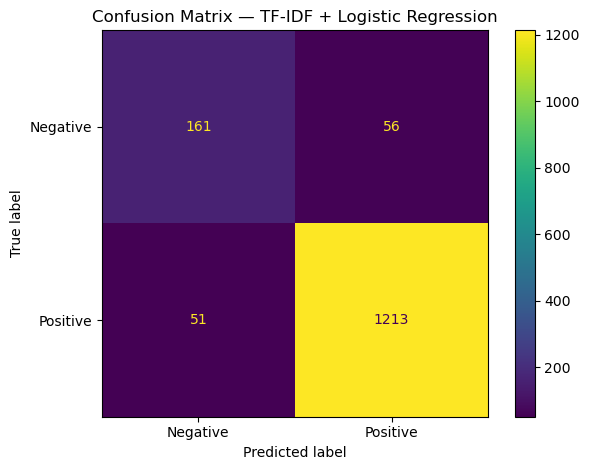

Saved to: C:\Users\Rafael Bantilan\OneDrive\Desktop\AI DATA\IE4483_MiniProject/results/figures/final_logistic_regression_confusion_matrix.png


In [16]:
lr_model = clone(lr_search.best_estimator_)

start_time = time.time()

lr_model.fit(
    train_df["clean_reviews"],
    y_train
)

lr_training_time = time.time() - start_time

lr_train_pred = lr_model.predict(train_df["clean_reviews"])
lr_val_pred = lr_model.predict(val_df["clean_reviews"])

lr_train_prob = lr_model.predict_proba(
    train_df["clean_reviews"]
)[:, 1]
lr_val_prob = lr_model.predict_proba(
    val_df["clean_reviews"]
)[:, 1]

lr_train_metrics = metric_dict(
    y_train,
    lr_train_pred,
    lr_train_prob
)

lr_val_metrics = metric_dict(
    y_val,
    lr_val_pred,
    lr_val_prob
)

lr_final_results = {
    "Model": "TF-IDF + Logistic Regression",
    "Feature Format": "TF-IDF",
    "Training Accuracy": lr_train_metrics["Accuracy"],
    "Validation Accuracy": lr_val_metrics["Accuracy"],
    "Precision": lr_val_metrics["Precision"],
    "Recall": lr_val_metrics["Recall"],
    "F1": lr_val_metrics["F1"],
    "Macro F1": lr_val_metrics["Macro F1"],
    "Macro F1 Std": np.nan,  # deterministic
    "Negative Recall": lr_val_metrics["Negative Recall"],
    "ROC-AUC": lr_val_metrics["ROC-AUC"],
    "Training Time (s)": lr_training_time,
    "Seeds": 1
}

display(pd.DataFrame([lr_final_results]).round(4))

print("\nValidation classification report")
print(classification_report(y_val, lr_val_pred, digits=4))

plot_confusion_matrix(
    y_val,
    lr_val_pred,
    "TF-IDF + Logistic Regression",
    "final_logistic_regression_confusion_matrix.png"
)

# Compatibility aliases used later in the notebook.
best_lr_pipeline = lr_model
best_vectorizer = lr_model.named_steps["tfidf"]
best_model = lr_model.named_steps["lr"]

joblib.dump(
    lr_model,
    f"{MODELS_DIR}/final_logistic_regression_holdout_model.joblib"
)

pd.DataFrame({
    "review": val_df["reviews"].values,
    "actual": y_val,
    "predicted": lr_val_pred,
    "probability_positive": lr_val_prob
}).to_csv(
    f"{METRICS_DIR}/logistic_validation_predictions.csv",
    index=False
)


# 8. TextCNN

## 8.1 Internal tuning split

TextCNN uses an internal split **inside `train_df`**:
- `cnn_fit_df`: updates model weights;
- `cnn_tune_df`: selects architecture, learning rate, dropout and stopping epoch;
- `val_df`: remains untouched until final evaluation.

This follows the same philosophy as the Linear SVM cross-validation: model settings are chosen without consulting the final holdout.


In [17]:
cnn_fit_df, cnn_tune_df = train_test_split(
    train_df,
    test_size=0.20,
    random_state=SEED,
    stratify=train_df["sentiments"]
)

cnn_fit_df = cnn_fit_df.reset_index(drop=True)
cnn_tune_df = cnn_tune_df.reset_index(drop=True)

print("CNN weight-fitting samples:", len(cnn_fit_df))
print("CNN internal tuning samples:", len(cnn_tune_df))
print("Untouched final holdout samples:", len(val_df))


CNN weight-fitting samples: 4736
CNN internal tuning samples: 1184
Untouched final holdout samples: 1481


## 8.2 TextCNN preprocessing

TextCNN does not use TF-IDF. It uses ordered token IDs followed by a learned embedding layer.

During tuning, the vocabulary is built from `cnn_fit_df` only.  
After hyperparameters are frozen, a new vocabulary is built from the full `train_df` for the final holdout model.


In [18]:
%%requires_torch
CNN_VOCAB_SIZE = 10000
CNN_MAX_LEN = 200

PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"
PAD_IDX = 0
UNK_IDX = 1


def cnn_tokenize(text):
    return re.findall(r"[a-z0-9']+", str(text).lower())


def build_vocab(texts, vocab_size=CNN_VOCAB_SIZE):
    counter = Counter()

    for text in texts:
        counter.update(cnn_tokenize(text))

    word_to_idx = {
        PAD_TOKEN: PAD_IDX,
        UNK_TOKEN: UNK_IDX
    }

    for word, _ in counter.most_common(vocab_size - 2):
        word_to_idx[word] = len(word_to_idx)

    return word_to_idx


def encode_text(text, word_to_idx, max_length=CNN_MAX_LEN):
    tokens = cnn_tokenize(text)

    ids = [
        word_to_idx.get(token, UNK_IDX)
        for token in tokens[:max_length]
    ]

    ids += [PAD_IDX] * (max_length - len(ids))
    return ids


def encode_series(texts, word_to_idx, max_length=CNN_MAX_LEN):
    return torch.tensor(
        [
            encode_text(text, word_to_idx, max_length)
            for text in texts
        ],
        dtype=torch.long
    )


# Tuning vocabulary: fit on cnn_fit_df only.
tune_word_to_idx = build_vocab(
    cnn_fit_df["clean_reviews"]
)

X_cnn_fit = encode_series(
    cnn_fit_df["clean_reviews"],
    tune_word_to_idx
)
X_cnn_tune = encode_series(
    cnn_tune_df["clean_reviews"],
    tune_word_to_idx
)

y_cnn_fit = torch.tensor(
    cnn_fit_df["sentiments"].values,
    dtype=torch.float32
)
y_cnn_tune = torch.tensor(
    cnn_tune_df["sentiments"].values,
    dtype=torch.float32
)

print("Tuning vocabulary size:", len(tune_word_to_idx))
print("CNN fit tensor:", X_cnn_fit.shape)
print("CNN tune tensor:", X_cnn_tune.shape)


Tuning vocabulary size: 10000
CNN fit tensor: torch.Size([4736, 200])
CNN tune tensor: torch.Size([1184, 200])


## 8.3 Single-kernel and multi-kernel TextCNN architectures

Both networks use:
token IDs → embedding → Conv1D → ReLU → global max pooling → dropout → linear output.

The multi-kernel version applies several Conv1D kernel sizes in parallel and concatenates the pooled features.


In [19]:
%%requires_torch
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("CNN device:", device)


class TextCNN(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim,
        num_filters,
        kernel_size,
        dropout
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=PAD_IDX
        )

        self.conv = nn.Conv1d(
            embedding_dim,
            num_filters,
            kernel_size
        )

        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(num_filters, 1)

    def forward(self, x):
        x = self.embedding(x)
        x = x.transpose(1, 2)
        x = F.relu(self.conv(x))
        x = F.adaptive_max_pool1d(x, 1).squeeze(2)
        x = self.dropout(x)
        return self.fc(x).squeeze(1)


class MultiKernelTextCNN(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim,
        num_filters,
        kernel_sizes,
        dropout
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=PAD_IDX
        )

        self.convs = nn.ModuleList([
            nn.Conv1d(
                embedding_dim,
                num_filters,
                kernel_size
            )
            for kernel_size in kernel_sizes
        ])

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            num_filters * len(kernel_sizes),
            1
        )

    def forward(self, x):
        x = self.embedding(x)
        x = x.transpose(1, 2)

        pooled = []

        for conv in self.convs:
            feature_map = F.relu(conv(x))
            pooled_feature = F.adaptive_max_pool1d(
                feature_map,
                1
            ).squeeze(2)
            pooled.append(pooled_feature)

        x = torch.cat(pooled, dim=1)
        x = self.dropout(x)
        return self.fc(x).squeeze(1)


CNN device: cuda


In [20]:
%%requires_torch
def make_loader(X, y=None, batch_size=64, shuffle=False, seed=SEED):
    # Seed controls the shuffle order
    generator = torch.Generator()
    generator.manual_seed(seed)

    if y is None:
        dataset = TensorDataset(X)
    else:
        dataset = TensorDataset(X, y)

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        generator=generator if shuffle else None,
        num_workers=0
    )


def build_cnn(config, vocab_size, multi_kernel=False):
    if multi_kernel:
        return MultiKernelTextCNN(
            vocab_size=vocab_size,
            embedding_dim=int(config["embedding_dim"]),
            num_filters=int(config["num_filters"]),
            kernel_sizes=list(config["kernel_sizes"]),
            dropout=float(config["dropout"])
        )

    return TextCNN(
        vocab_size=vocab_size,
        embedding_dim=int(config["embedding_dim"]),
        num_filters=int(config["num_filters"]),
        kernel_size=int(config["kernel_size"]),
        dropout=float(config["dropout"])
    )


@torch.no_grad()
def predict_cnn_labeled(model, X, y, batch_size):
    loader = make_loader(
        X,
        y,
        batch_size=batch_size,
        shuffle=False
    )

    model.eval()

    probabilities = []
    labels = []

    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device)

        logits = model(X_batch)
        prob = torch.sigmoid(logits)

        probabilities.extend(prob.cpu().numpy())
        labels.extend(y_batch.numpy())

    y_true = np.asarray(labels, dtype=int)
    y_prob = np.asarray(probabilities)
    y_pred = (y_prob >= 0.5).astype(int)

    return y_true, y_prob, y_pred


@torch.no_grad()
def predict_cnn_unlabeled(model, X, batch_size):
    loader = make_loader(
        X,
        y=None,
        batch_size=batch_size,
        shuffle=False
    )

    model.eval()
    probabilities = []

    for (X_batch,) in loader:
        X_batch = X_batch.to(device)

        logits = model(X_batch)
        prob = torch.sigmoid(logits)

        probabilities.extend(prob.cpu().numpy())

    y_prob = np.asarray(probabilities)
    y_pred = (y_prob >= 0.5).astype(int)

    return y_pred, y_prob


def evaluate_cnn(model, X, y, batch_size):
    y_true, y_prob, y_pred = predict_cnn_labeled(
        model,
        X,
        y,
        batch_size
    )

    metrics = metric_dict(
        y_true,
        y_pred,
        y_prob
    )

    return metrics, y_true, y_prob, y_pred


## 8.4 CNN training functions

Early stopping is used **only on the internal tuning split**.
Its purpose is to estimate a suitable epoch count without looking at the final holdout.

Two additions make the TextCNN comparison fair and reproducible:

- **Class weighting** (`class_weight = None` or `"balanced"`) is a tuned option, as it is for Logistic Regression and the Linear SVM.
  `BCEWithLogitsLoss` can only weight the positive class, so `"balanced"` sets `pos_weight = n_negative / n_positive` (≈ 0.17).
  This down-weights the majority positive class and gives the same relative class weights as scikit-learn's `"balanced"`.
- **Multiple seeds.** Network training is random (initial weights, batch order, dropout), and a single run can move macro-F1 by
  about ±0.016 on this data. Each tuning candidate is therefore trained with **3 seeds** (`TUNING_SEEDS`) and judged on the
  **mean** tuning macro-F1; the selected epoch count is the rounded mean of the per-seed best epochs.

After settings are selected, the final holdout models are trained on the whole `train_df` for the fixed selected number of epochs,
with no holdout-based early stopping, using **5 seeds** (`FINAL_SEEDS`).


In [21]:
%%requires_torch
TUNING_SEEDS = [42, 43, 44]
FINAL_SEEDS = [42, 43, 44, 45, 46]


def make_criterion(config, y_labels):
    # Down-weight the majority positive class
    if config.get("class_weight") == "balanced":
        n_pos = float(y_labels.sum())
        n_neg = float(len(y_labels)) - n_pos
        pos_weight = torch.tensor([n_neg / n_pos], device=device)
        return nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    return nn.BCEWithLogitsLoss()


def train_cnn_for_tuning(
    config,
    vocab_size,
    X_fit,
    y_fit,
    X_tune,
    y_tune,
    multi_kernel=False,
    seed=SEED
):
    set_seed(seed)

    model = build_cnn(
        config,
        vocab_size,
        multi_kernel=multi_kernel
    ).to(device)

    train_loader = make_loader(
        X_fit,
        y_fit,
        batch_size=int(config["batch_size"]),
        shuffle=True,
        seed=seed
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=float(config["learning_rate"])
    )

    criterion = make_criterion(config, y_fit)

    max_epochs = int(config["epochs"])
    patience = int(config.get("patience", 2))

    best_state = None
    best_macro_f1 = -np.inf
    best_accuracy = -np.inf
    best_epoch = 0
    patience_counter = 0

    start_time = time.time()

    for epoch in range(1, max_epochs + 1):
        model.train()

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            logits = model(X_batch)
            loss = criterion(logits, y_batch)

            loss.backward()
            optimizer.step()

        tune_metrics, _, _, _ = evaluate_cnn(
            model,
            X_tune,
            y_tune,
            int(config["batch_size"])
        )

        current_macro = tune_metrics["Macro F1"]
        current_accuracy = tune_metrics["Accuracy"]

        improved = (
            current_macro > best_macro_f1 + 1e-12
            or (
                abs(current_macro - best_macro_f1) <= 1e-12
                and current_accuracy > best_accuracy
            )
        )

        if improved:
            best_macro_f1 = current_macro
            best_accuracy = current_accuracy
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= patience:
            break

    training_time = time.time() - start_time

    model.load_state_dict(best_state)

    best_metrics, _, _, _ = evaluate_cnn(
        model,
        X_tune,
        y_tune,
        int(config["batch_size"])
    )

    best_metrics["Best Epoch"] = best_epoch
    best_metrics["Training Time (s)"] = training_time

    return model, best_metrics


def tune_cnn_multi_seed(
    config,
    vocab_size,
    X_fit,
    y_fit,
    X_tune,
    y_tune,
    multi_kernel=False,
    seeds=TUNING_SEEDS
):
    # Average the metrics over the seeds
    seed_rows = []

    for seed in seeds:
        model, metrics = train_cnn_for_tuning(
            config,
            vocab_size,
            X_fit,
            y_fit,
            X_tune,
            y_tune,
            multi_kernel=multi_kernel,
            seed=seed
        )
        seed_rows.append(metrics)

        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    seed_df = pd.DataFrame(seed_rows)

    summary = seed_df.mean(numeric_only=True).to_dict()
    summary["Macro F1 Std"] = seed_df["Macro F1"].std()
    summary["Best Epoch"] = int(round(seed_df["Best Epoch"].mean()))
    summary["Best Epochs per Seed"] = str(seed_df["Best Epoch"].tolist())
    summary["Training Time (s)"] = seed_df["Training Time (s)"].sum()

    return summary


def train_cnn_fixed_epochs(
    config,
    vocab_size,
    X_train,
    y_train_tensor,
    epochs,
    multi_kernel=False,
    seed=SEED
):
    set_seed(seed)

    model = build_cnn(
        config,
        vocab_size,
        multi_kernel=multi_kernel
    ).to(device)

    train_loader = make_loader(
        X_train,
        y_train_tensor,
        batch_size=int(config["batch_size"]),
        shuffle=True,
        seed=seed
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=float(config["learning_rate"])
    )

    criterion = make_criterion(config, y_train_tensor)

    start_time = time.time()

    for _ in range(int(epochs)):
        model.train()

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            logits = model(X_batch)
            loss = criterion(logits, y_batch)

            loss.backward()
            optimizer.step()

    training_time = time.time() - start_time

    return model, training_time


## 8.5 Single-kernel TextCNN hyperparameter experiment

A controlled sequential search is performed on the internal tuning split.
At each stage, only one parameter changes and the best value is carried forward.
Class weighting is tuned first because it changes how the loss treats the minority negative class, which affects every later choice.

Every candidate is trained with 3 seeds (`TUNING_SEEDS`).
Primary criterion: **mean** internal tuning macro-F1. Secondary criterion: mean internal tuning accuracy.


In [22]:
%%requires_torch
baseline_cnn_config = {
    "class_weight": None,
    "embedding_dim": 128,
    "num_filters": 128,
    "kernel_size": 3,
    "dropout": 0.3,
    "learning_rate": 0.001,
    "batch_size": 64,
    "epochs": 12,  # cap only
    "patience": 2
}

baseline_cnn_metrics = tune_cnn_multi_seed(
    baseline_cnn_config,
    vocab_size=len(tune_word_to_idx),
    X_fit=X_cnn_fit,
    y_fit=y_cnn_fit,
    X_tune=X_cnn_tune,
    y_tune=y_cnn_tune,
    multi_kernel=False
)

print(f"Baseline TextCNN — internal tuning split (mean of {len(TUNING_SEEDS)} seeds)")
display(pd.DataFrame([{
    **baseline_cnn_config,
    **baseline_cnn_metrics
}]).round(4))


Baseline TextCNN — internal tuning split (mean of 3 seeds)


,class_weight,embedding_dim,num_filters,kernel_size,dropout,learning_rate,batch_size,epochs,patience,Accuracy,Precision,Recall,F1,Macro F1,Negative Recall,ROC-AUC,Best Epoch,Training Time (s),Macro F1 Std,Best Epochs per Seed
0,None,128,128,3,0.3,0.001,64,12,2,0.9006,0.9154,0.9736,0.9436,0.7628,0.474,0.9248,6,5.4283,0.007,"[5, 6, 8]"


In [23]:
%%requires_torch
tuning_plan = [
    ("class_weight", [None, "balanced"]),
    ("kernel_size", [2, 3, 4, 5]),
    ("num_filters", [64, 128, 256]),
    ("embedding_dim", [64, 128, 256]),
    ("learning_rate", [0.0001, 0.001, 0.01]),
    ("dropout", [0.2, 0.3, 0.5])
]

best_cnn_config = baseline_cnn_config.copy()
cnn_experiment_results = []
selected_cnn_epochs = None

for parameter, values in tuning_plan:
    stage_results = []

    for value in tqdm(
        values,
        desc=f"Tuning {parameter}",
        unit="config"
    ):
        config = best_cnn_config.copy()
        config[parameter] = value

        metrics = tune_cnn_multi_seed(
            config,
            vocab_size=len(tune_word_to_idx),
            X_fit=X_cnn_fit,
            y_fit=y_cnn_fit,
            X_tune=X_cnn_tune,
            y_tune=y_cnn_tune,
            multi_kernel=False
        )

        result = {
            "Parameter Tuned": parameter,
            **config,
            **metrics
        }

        stage_results.append(result)
        cnn_experiment_results.append(result)

    stage_df = pd.DataFrame(stage_results).sort_values(
        ["Macro F1", "Accuracy"],
        ascending=[False, False]
    ).reset_index(drop=True)

    selected_value = stage_df.loc[0, parameter]

    if parameter == "class_weight":
        selected_value = None if pd.isna(selected_value) else str(selected_value)
    elif parameter in {
        "kernel_size",
        "num_filters",
        "embedding_dim",
        "batch_size",
        "epochs"
    }:
        selected_value = int(selected_value)
    else:
        selected_value = float(selected_value)

    best_cnn_config[parameter] = selected_value
    selected_cnn_epochs = int(stage_df.loc[0, "Best Epoch"])

    print(
        f"Selected {parameter}: {selected_value} | "
        f"mean tune macro-F1={stage_df.loc[0, 'Macro F1']:.4f} "
        f"± {stage_df.loc[0, 'Macro F1 Std']:.4f} | "
        f"mean accuracy={stage_df.loc[0, 'Accuracy']:.4f}"
    )

cnn_experiment_results_df = pd.DataFrame(
    cnn_experiment_results
)

cnn_experiment_path = (
    f"{EXPERIMENTS_DIR}/"
    "textcnn_internal_tuning_experiments.csv"
)

cnn_experiment_results_df.to_csv(
    cnn_experiment_path,
    index=False
)

print("\nFinal single-kernel configuration:")
for key, value in best_cnn_config.items():
    print(f"  {key}: {value}")

print("Selected fixed epoch count:", selected_cnn_epochs)

# Warn if the epoch cap was reached
best_epochs = eval(stage_df.loc[0, "Best Epochs per Seed"])
if max(best_epochs) >= int(best_cnn_config["epochs"]):
    print(f"NOTE: a seed's best epoch reached the cap of {best_cnn_config['epochs']} epochs.")

print("Saved:", cnn_experiment_path)


Tuning class_weight:   0%|          | 0/2 [00:00<?, ?config/s]

Selected class_weight: balanced | mean tune macro-F1=0.8038 ± 0.0041 | mean accuracy=0.8989


Tuning kernel_size:   0%|          | 0/4 [00:00<?, ?config/s]

Selected kernel_size: 2 | mean tune macro-F1=0.8120 ± 0.0046 | mean accuracy=0.8967


Tuning num_filters:   0%|          | 0/3 [00:00<?, ?config/s]

Selected num_filters: 256 | mean tune macro-F1=0.8122 ± 0.0121 | mean accuracy=0.9015


... (2 outputs left out)

Tuning learning_rate:   0%|          | 0/3 [00:00<?, ?config/s]

Selected learning_rate: 0.001 | mean tune macro-F1=0.8286 ± 0.0084 | mean accuracy=0.9096


Tuning dropout:   0%|          | 0/3 [00:00<?, ?config/s]

Selected dropout: 0.2 | mean tune macro-F1=0.8294 ± 0.0067 | mean accuracy=0.9119

Final single-kernel configuration:
  class_weight: balanced
  embedding_dim: 256
  num_filters: 256
  kernel_size: 2
  dropout: 0.2
  learning_rate: 0.001
  batch_size: 64
  epochs: 12
  patience: 2
Selected fixed epoch count: 6
Saved: C:\Users\Rafael Bantilan\OneDrive\Desktop\AI DATA\IE4483_MiniProject/results/experiments/textcnn_internal_tuning_experiments.csv


## 8.6 Multi-kernel TextCNN experiment

The best single-kernel settings (including class weighting) are kept fixed while only the parallel kernel set changes.
Selection again uses the internal tuning split only, with each kernel set averaged over 3 seeds.


In [24]:
%%requires_torch
kernel_sets = [
    [2, 3, 4],
    [3, 4, 5],
    [2, 3, 4, 5]
]

multikernel_results = []

for kernel_sizes in tqdm(
    kernel_sets,
    desc="Testing multi-kernel TextCNN",
    unit="config"
):
    config = best_cnn_config.copy()
    config.pop("kernel_size", None)
    config["kernel_sizes"] = kernel_sizes

    metrics = tune_cnn_multi_seed(
        config,
        vocab_size=len(tune_word_to_idx),
        X_fit=X_cnn_fit,
        y_fit=y_cnn_fit,
        X_tune=X_cnn_tune,
        y_tune=y_cnn_tune,
        multi_kernel=True
    )

    multikernel_results.append({
        "Kernel Sizes": str(kernel_sizes),
        **config,
        **metrics
    })

multikernel_results_df = pd.DataFrame(
    multikernel_results
).sort_values(
    ["Macro F1", "Accuracy"],
    ascending=[False, False]
).reset_index(drop=True)

display(
    multikernel_results_df[
        [
            "Kernel Sizes",
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "Macro F1",
            "Macro F1 Std",
            "Negative Recall",
            "ROC-AUC",
            "Best Epoch",
            "Best Epochs per Seed",
            "Training Time (s)"
        ]
    ].round(4)
)

best_kernel_sizes = eval(
    multikernel_results_df.loc[0, "Kernel Sizes"]
)

best_multikernel_config = best_cnn_config.copy()
best_multikernel_config.pop("kernel_size", None)
best_multikernel_config["kernel_sizes"] = best_kernel_sizes

selected_multikernel_epochs = int(
    multikernel_results_df.loc[0, "Best Epoch"]
)

multikernel_path = (
    f"{EXPERIMENTS_DIR}/"
    "multikernel_textcnn_internal_tuning.csv"
)

multikernel_results_df.to_csv(
    multikernel_path,
    index=False
)

print("Selected kernel set:", best_kernel_sizes)
print("Selected fixed epoch count:", selected_multikernel_epochs)
print("Saved:", multikernel_path)


Testing multi-kernel TextCNN:   0%|          | 0/3 [00:00<?, ?config/s]

,Kernel Sizes,Accuracy,Precision,Recall,F1,Macro F1,Macro F1 Std,Negative Recall,ROC-AUC,Best Epoch,Best Epochs per Seed,Training Time (s)
0,"[2, 3, 4]",0.8998,0.9601,0.9209,0.9401,0.8168,0.0075,0.7765,0.9345,4,"[5, 4, 3]",15.4990
1,"[2, 3, 4, 5]",0.9023,0.9502,0.9347,0.9423,0.8114,0.0044,0.7129,0.9336,5,"[3, 6, 5]",21.1014
2,"[3, 4, 5]",0.9034,0.9449,0.9420,0.9433,0.8077,0.0022,0.6782,0.9301,5,"[5, 4, 6]",18.9074


Selected kernel set: [2, 3, 4]
Selected fixed epoch count: 4
Saved: C:\Users\Rafael Bantilan\OneDrive\Desktop\AI DATA\IE4483_MiniProject/results/experiments/multikernel_textcnn_internal_tuning.csv


## 8.7 Rebuild the CNN representation from the full `train_df`

Hyperparameters are now frozen.  
The final CNN vocabulary is built from all 5,920 training-split reviews, **not from `val_df`**.

Both final CNNs are then trained for their fixed selected epoch counts with no holdout-based early stopping.


In [25]:
%%requires_torch
final_word_to_idx = build_vocab(
    train_df["clean_reviews"]
)

X_train_cnn_final = encode_series(
    train_df["clean_reviews"],
    final_word_to_idx
)

X_val_cnn_final = encode_series(
    val_df["clean_reviews"],
    final_word_to_idx
)

X_test_cnn_final = encode_series(
    test_df["clean_reviews"],
    final_word_to_idx
)

y_train_cnn_final = torch.tensor(
    y_train,
    dtype=torch.float32
)

y_val_cnn_final = torch.tensor(
    y_val,
    dtype=torch.float32
)

print("Final training vocabulary size:", len(final_word_to_idx))
print("Training tensor:", X_train_cnn_final.shape)
print("Final holdout tensor:", X_val_cnn_final.shape)
print("Test tensor:", X_test_cnn_final.shape)


Final training vocabulary size: 10000
Training tensor: torch.Size([5920, 200])
Final holdout tensor: torch.Size([1481, 200])
Test tensor: torch.Size([1851, 200])


## 8.8 Final single-kernel TextCNN — holdout evaluation over 5 seeds

The frozen configuration is trained once per seed in `FINAL_SEEDS` on the full `train_df` and evaluated once on `val_df`.
The comparison table reports the **mean** (with the macro-F1 standard deviation); the seed-42 model is kept for the confusion matrix, error analysis and the Section 15 refit.


TextCNN — final holdout, one row per seed


,Seed,Training Accuracy,Accuracy,Precision,Recall,F1,Macro F1,Negative Recall,ROC-AUC,Training Time (s)
0,42,0.9958,0.9244,0.9608,0.9502,0.9554,0.8527,0.7742,0.9435,2.2059
1,43,0.9954,0.9291,0.9603,0.9565,0.9584,0.8596,0.7696,0.9423,2.1253
2,44,0.9922,0.9142,0.9687,0.9296,0.9487,0.8434,0.8249,0.9411,2.1431
3,45,0.9971,0.9190,0.9540,0.9509,0.9525,0.8392,0.7327,0.9388,2.1275
4,46,0.9975,0.9230,0.9478,0.9628,0.9553,0.8399,0.6912,0.9418,2.1615



Mean ± std over 5 seeds:
  Accuracy: 0.9219 ± 0.0056
  Macro F1: 0.8470 ± 0.0089
  Negative Recall: 0.7585 ± 0.0499
  ROC-AUC: 0.9415 ± 0.0017

Validation classification report (seed 42 model)
              precision    recall  f1-score   support

           0     0.7273    0.7742    0.7500       217
           1     0.9608    0.9502    0.9554      1264

    accuracy                         0.9244      1481
   macro avg     0.8440    0.8622    0.8527      1481
weighted avg     0.9266    0.9244    0.9253      1481



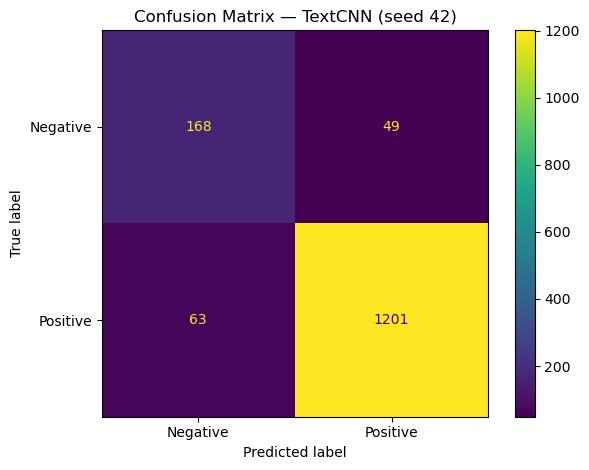

Saved to: C:\Users\Rafael Bantilan\OneDrive\Desktop\AI DATA\IE4483_MiniProject/results/figures/final_textcnn_confusion_matrix.png


In [26]:
%%requires_torch
# Train with each seed and evaluate once on the holdout
cnn_seed_rows = []

for seed in FINAL_SEEDS:
    model, train_time = train_cnn_fixed_epochs(
        config=best_cnn_config,
        vocab_size=len(final_word_to_idx),
        X_train=X_train_cnn_final,
        y_train_tensor=y_train_cnn_final,
        epochs=selected_cnn_epochs,
        multi_kernel=False,
        seed=seed
    )

    train_metrics, _, _, _ = evaluate_cnn(
        model,
        X_train_cnn_final,
        y_train_cnn_final,
        int(best_cnn_config["batch_size"])
    )

    val_metrics, _, val_prob, val_pred = evaluate_cnn(
        model,
        X_val_cnn_final,
        y_val_cnn_final,
        int(best_cnn_config["batch_size"])
    )

    cnn_seed_rows.append({
        "Seed": seed,
        "Training Accuracy": train_metrics["Accuracy"],
        **val_metrics,
        "Training Time (s)": train_time
    })

    if seed == SEED:
        final_cnn_model = model
        cnn_training_time = train_time
        cnn_val_metrics = val_metrics
        cnn_val_prob = val_prob
        cnn_val_pred = val_pred
    else:
        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

cnn_seed_df = pd.DataFrame(cnn_seed_rows)

print(f"TextCNN — final holdout, one row per seed")
display(cnn_seed_df.round(4))

cnn_seed_df.to_csv(
    f"{METRICS_DIR}/cnn_holdout_by_seed.csv",
    index=False
)

cnn_mean = cnn_seed_df.drop(columns="Seed").mean()
cnn_std = cnn_seed_df.drop(columns="Seed").std()

cnn_final_results = {
    "Model": "TextCNN",
    "Feature Format": "Token Sequence + Learned Embedding",
    "Training Accuracy": cnn_mean["Training Accuracy"],
    "Validation Accuracy": cnn_mean["Accuracy"],
    "Precision": cnn_mean["Precision"],
    "Recall": cnn_mean["Recall"],
    "F1": cnn_mean["F1"],
    "Macro F1": cnn_mean["Macro F1"],
    "Macro F1 Std": cnn_std["Macro F1"],
    "Negative Recall": cnn_mean["Negative Recall"],
    "ROC-AUC": cnn_mean["ROC-AUC"],
    "Training Time (s)": cnn_mean["Training Time (s)"],
    "Seeds": len(FINAL_SEEDS)
}

print(f"\nMean ± std over {len(FINAL_SEEDS)} seeds:")
for metric in ["Accuracy", "Macro F1", "Negative Recall", "ROC-AUC"]:
    print(f"  {metric}: {cnn_mean[metric]:.4f} ± {cnn_std[metric]:.4f}")

print(f"\nValidation classification report (seed {SEED} model)")
print(classification_report(y_val, cnn_val_pred, digits=4))

plot_confusion_matrix(
    y_val,
    cnn_val_pred,
    f"TextCNN (seed {SEED})",
    "final_textcnn_confusion_matrix.png"
)

torch.save({
    "model_state_dict": final_cnn_model.state_dict(),
    "config": best_cnn_config,
    "selected_epochs": selected_cnn_epochs,
    "seed": SEED,
    "word_to_idx": final_word_to_idx,
    "max_sequence_length": CNN_MAX_LEN
}, f"{MODELS_DIR}/final_textcnn_holdout_model.pt")


## 8.9 Final multi-kernel TextCNN — holdout evaluation over 5 seeds

Same procedure as 8.8.


Multi-Kernel TextCNN — final holdout, one row per seed


,Seed,Training Accuracy,Accuracy,Precision,Recall,F1,Macro F1,Negative Recall,ROC-AUC,Training Time (s)
0,42,0.9959,0.9142,0.9679,0.9304,0.9488,0.8429,0.8203,0.9399,3.5318
1,43,0.9995,0.9291,0.9531,0.9644,0.9587,0.8541,0.7235,0.9400,3.4328
2,44,0.9998,0.9149,0.9431,0.9581,0.9505,0.8231,0.6636,0.9318,3.4118
3,45,0.9995,0.9176,0.9359,0.9699,0.9526,0.8191,0.6129,0.9344,3.4149
4,46,0.9995,0.9115,0.9521,0.9438,0.9480,0.8268,0.7235,0.9373,3.5560



Mean ± std over 5 seeds:
  Accuracy: 0.9175 ± 0.0068
  Macro F1: 0.8332 ± 0.0148
  Negative Recall: 0.7088 ± 0.0776
  ROC-AUC: 0.9367 ± 0.0036

Validation classification report (seed 42 model)
              precision    recall  f1-score   support

           0     0.6692    0.8203    0.7371       217
           1     0.9679    0.9304    0.9488      1264

    accuracy                         0.9142      1481
   macro avg     0.8185    0.8753    0.8429      1481
weighted avg     0.9241    0.9142    0.9177      1481



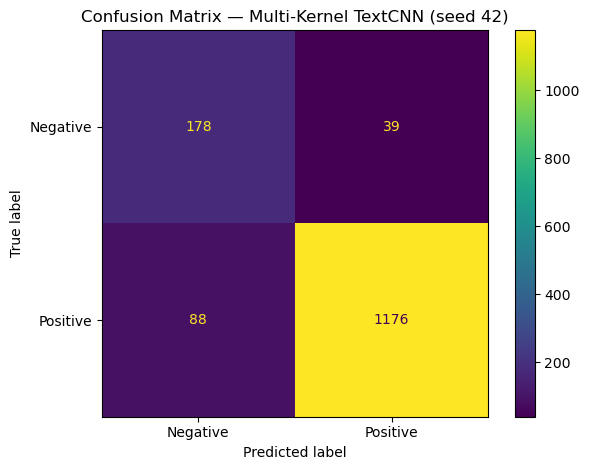

Saved to: C:\Users\Rafael Bantilan\OneDrive\Desktop\AI DATA\IE4483_MiniProject/results/figures/final_multikernel_textcnn_confusion_matrix.png


In [27]:
%%requires_torch
# Train with each seed and evaluate once on the holdout
multi_seed_rows = []

for seed in FINAL_SEEDS:
    model, train_time = train_cnn_fixed_epochs(
        config=best_multikernel_config,
        vocab_size=len(final_word_to_idx),
        X_train=X_train_cnn_final,
        y_train_tensor=y_train_cnn_final,
        epochs=selected_multikernel_epochs,
        multi_kernel=True,
        seed=seed
    )

    train_metrics, _, _, _ = evaluate_cnn(
        model,
        X_train_cnn_final,
        y_train_cnn_final,
        int(best_multikernel_config["batch_size"])
    )

    val_metrics, _, val_prob, val_pred = evaluate_cnn(
        model,
        X_val_cnn_final,
        y_val_cnn_final,
        int(best_multikernel_config["batch_size"])
    )

    multi_seed_rows.append({
        "Seed": seed,
        "Training Accuracy": train_metrics["Accuracy"],
        **val_metrics,
        "Training Time (s)": train_time
    })

    if seed == SEED:
        final_multikernel_model = model
        multikernel_training_time = train_time
        multi_val_metrics = val_metrics
        multi_val_prob = val_prob
        multi_val_pred = val_pred
    else:
        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

multi_seed_df = pd.DataFrame(multi_seed_rows)

print(f"Multi-Kernel TextCNN — final holdout, one row per seed")
display(multi_seed_df.round(4))

multi_seed_df.to_csv(
    f"{METRICS_DIR}/multi_holdout_by_seed.csv",
    index=False
)

multi_mean = multi_seed_df.drop(columns="Seed").mean()
multi_std = multi_seed_df.drop(columns="Seed").std()

multikernel_final_results = {
    "Model": "Multi-Kernel TextCNN",
    "Feature Format": "Token Sequence + Learned Embedding",
    "Training Accuracy": multi_mean["Training Accuracy"],
    "Validation Accuracy": multi_mean["Accuracy"],
    "Precision": multi_mean["Precision"],
    "Recall": multi_mean["Recall"],
    "F1": multi_mean["F1"],
    "Macro F1": multi_mean["Macro F1"],
    "Macro F1 Std": multi_std["Macro F1"],
    "Negative Recall": multi_mean["Negative Recall"],
    "ROC-AUC": multi_mean["ROC-AUC"],
    "Training Time (s)": multi_mean["Training Time (s)"],
    "Seeds": len(FINAL_SEEDS)
}

print(f"\nMean ± std over {len(FINAL_SEEDS)} seeds:")
for metric in ["Accuracy", "Macro F1", "Negative Recall", "ROC-AUC"]:
    print(f"  {metric}: {multi_mean[metric]:.4f} ± {multi_std[metric]:.4f}")

print(f"\nValidation classification report (seed {SEED} model)")
print(classification_report(y_val, multi_val_pred, digits=4))

plot_confusion_matrix(
    y_val,
    multi_val_pred,
    f"Multi-Kernel TextCNN (seed {SEED})",
    "final_multikernel_textcnn_confusion_matrix.png"
)

torch.save({
    "model_state_dict": final_multikernel_model.state_dict(),
    "config": best_multikernel_config,
    "selected_epochs": selected_multikernel_epochs,
    "seed": SEED,
    "word_to_idx": final_word_to_idx,
    "max_sequence_length": CNN_MAX_LEN
}, f"{MODELS_DIR}/final_multikernel_textcnn_holdout_model.pt")


# 9. TF-IDF + Linear SVM

A linear SVM on TF-IDF features, tuned with 5-fold cross-validation inside `train_df` (same as Logistic Regression).
`val_df` is only used once, in 9.2.

| Setting | Values |
|---|---|
| `C` | 0.01, 0.05, 0.1, 0.5, 1, 5, 10 |
| `class_weight` | None, balanced |
| `ngram_range` | (1,1), (1,2), (1,3) |
| `sublinear_tf` | False, True |

TF-IDF is capped at 10,000 features. Selection metric: mean CV macro-F1.


## 9.1 Training-only grid search (5-fold CV)


In [28]:
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.base import clone
from sklearn.metrics import make_scorer

# TF-IDF + Linear SVM
# Vectorizer is fitted on the training folds only
svm_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=10000,
        lowercase=False
    )),
    ("svm", LinearSVC(
        random_state=SEED,
        max_iter=10000
    ))
])

svm_param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2), (1, 3)],
    "tfidf__sublinear_tf": [False, True],
    "svm__C": [0.01, 0.05, 0.1, 0.5, 1, 5, 10],
    "svm__class_weight": [None, "balanced"]
}

# Select on macro-F1
svm_scoring = {
    "macro_f1": "f1_macro",
    "accuracy": "accuracy",
    "positive_f1": "f1",
    "negative_recall": make_scorer(recall_score, pos_label=0),
    "negative_precision": make_scorer(
        precision_score, pos_label=0, zero_division=0
    )
}

svm_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

svm_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_param_grid,
    scoring=svm_scoring,
    refit="macro_f1",
    cv=svm_cv,
    n_jobs=-1,
    return_train_score=True
)

start_time = time.time()

svm_search.fit(
    train_df["clean_reviews"],
    y_train
)

svm_search_time = time.time() - start_time

n_configs = len(svm_search.cv_results_["params"])

print(f"Grid search finished in {svm_search_time:.1f} seconds")
print(f"Configurations evaluated: {n_configs} x 5 folds = {n_configs * 5} fits")
print("\nBest configuration (by mean CV macro-F1):")
for param, value in svm_search.best_params_.items():
    print(f"  {param}: {value}")
print(f"Best mean CV macro-F1: {svm_search.best_score_:.4f}")

Grid search finished in 73.0 seconds
Configurations evaluated: 84 x 5 folds = 420 fits

Best configuration (by mean CV macro-F1):
  svm__C: 0.5
  svm__class_weight: balanced
  tfidf__ngram_range: (1, 2)
  tfidf__sublinear_tf: True
Best mean CV macro-F1: 0.8430


In [29]:
# Grid search results
cv_res = svm_search.cv_results_

svm_grid_df = pd.DataFrame({
    "ngram_range": [str(p["tfidf__ngram_range"]) for p in cv_res["params"]],
    "sublinear_tf": [p["tfidf__sublinear_tf"] for p in cv_res["params"]],
    "C": [p["svm__C"] for p in cv_res["params"]],
    "class_weight": [str(p["svm__class_weight"]) for p in cv_res["params"]],
    "CV_Macro_F1": cv_res["mean_test_macro_f1"],
    "CV_Macro_F1_std": cv_res["std_test_macro_f1"],
    "CV_Accuracy": cv_res["mean_test_accuracy"],
    "CV_Positive_F1": cv_res["mean_test_positive_f1"],
    "CV_Negative_Recall": cv_res["mean_test_negative_recall"],
    "CV_Negative_Precision": cv_res["mean_test_negative_precision"],
    "Train_Macro_F1": cv_res["mean_train_macro_f1"],
    "Fit_Time_s": cv_res["mean_fit_time"]
})

svm_grid_df = (
    svm_grid_df
    .sort_values("CV_Macro_F1", ascending=False)
    .reset_index(drop=True)
)

svm_grid_path = f"{EXPERIMENTS_DIR}/svm_grid_search_results.csv"
svm_grid_df.to_csv(svm_grid_path, index=False)

print("Top 10 Linear SVM configurations (5-fold CV on training split)")
display(svm_grid_df.head(10).round(4))

print("\nBest configuration per class_weight setting:")
display(
    svm_grid_df
    .groupby("class_weight", as_index=False)
    .first()
    .round(4)
)

print("Saved full grid results to:", svm_grid_path)

Top 10 Linear SVM configurations (5-fold CV on training split)


,ngram_range,sublinear_tf,C,class_weight,CV_Macro_F1,CV_Macro_F1_std,CV_Accuracy,CV_Positive_F1,CV_Negative_Recall,CV_Negative_Precision,Train_Macro_F1,Fit_Time_s
0,"(1, 2)",True,0.5,balanced,0.8430,0.0028,0.9206,0.9534,0.7445,0.7216,0.9820,1.1839
1,"(1, 3)",True,0.5,balanced,0.8421,0.0078,0.9199,0.9530,0.7457,0.7178,0.9815,2.4469
2,"(1, 2)",False,0.5,balanced,0.8388,0.0060,0.9181,0.9518,0.7422,0.7103,0.9795,1.1204
3,"(1, 3)",True,1.0,balanced,0.8367,0.0060,0.9196,0.9530,0.7087,0.7327,0.9958,2.4541
4,"(1, 3)",False,0.5,balanced,0.8361,0.0040,0.9162,0.9507,0.7434,0.7013,0.9790,2.4272
5,"(1, 2)",False,1.0,balanced,0.8359,0.0070,0.9189,0.9526,0.7110,0.7281,0.9951,1.0873
6,"(1, 2)",True,1.0,balanced,0.8356,0.0097,0.9194,0.9530,0.7029,0.7351,0.9961,1.1543
7,"(1, 3)",False,1.0,balanced,0.8341,0.0047,0.9177,0.9519,0.7110,0.7219,0.9945,2.3593
8,"(1, 1)",True,0.5,balanced,0.8303,0.0035,0.9111,0.9474,0.7561,0.6763,0.9662,0.3336
9,"(1, 2)",True,0.1,balanced,0.8293,0.0050,0.9064,0.9440,0.8012,0.6454,0.9254,1.0436



Best configuration per class_weight setting:


,class_weight,ngram_range,sublinear_tf,C,CV_Macro_F1,CV_Macro_F1_std,CV_Accuracy,CV_Positive_F1,CV_Negative_Recall,CV_Negative_Precision,Train_Macro_F1,Fit_Time_s
0,None,"(1, 3)",True,5.0,0.8169,0.0139,0.9171,0.9523,0.6081,0.7754,1.000,2.4172
1,balanced,"(1, 2)",True,0.5,0.8430,0.0028,0.9206,0.9534,0.7445,0.7216,0.982,1.1839


Saved full grid results to: C:\Users\Rafael Bantilan\OneDrive\Desktop\AI DATA\IE4483_MiniProject/results/experiments/svm_grid_search_results.csv


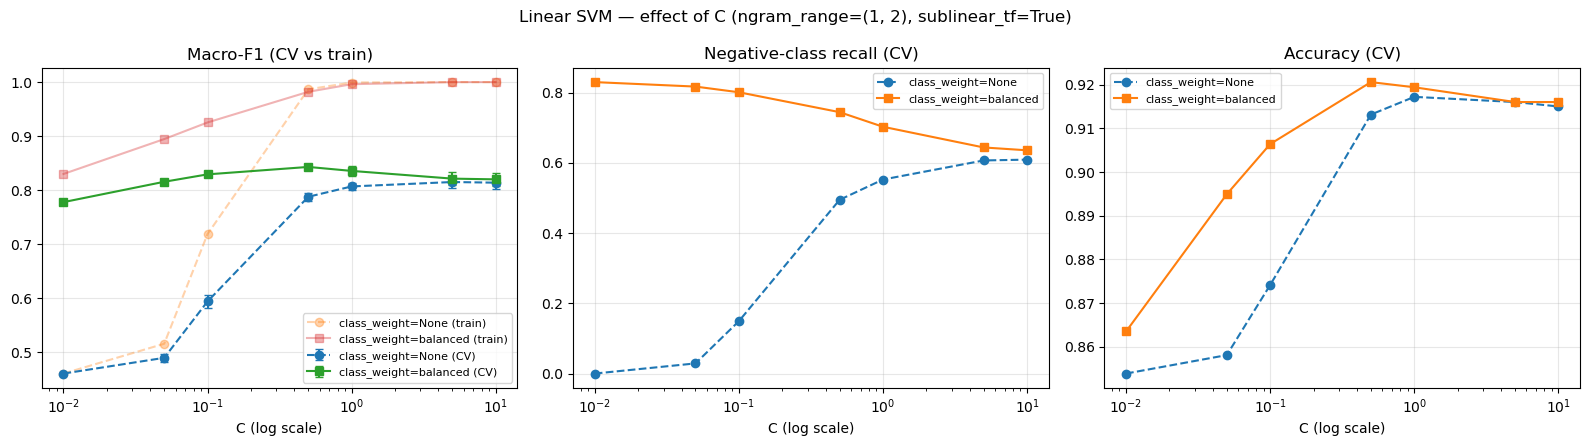

Saved to: C:\Users\Rafael Bantilan\OneDrive\Desktop\AI DATA\IE4483_MiniProject/results/figures/svm_c_sweep.png


,class_weight,C,CV_Macro_F1,Train_Macro_F1,CV_Negative_Recall,CV_Negative_Precision,CV_Accuracy
60,balanced,0.01,0.7779,0.8300,0.8301,0.5216,0.8635
81,None,0.01,0.4606,0.4606,0.0000,0.0000,0.8539
24,balanced,0.05,0.8155,0.8946,0.8173,0.6042,0.8949
77,None,0.05,0.4897,0.5157,0.0289,1.0000,0.8581
9,balanced,0.10,0.8293,0.9254,0.8012,0.6454,0.9064
71,None,0.10,0.5941,0.7189,0.1491,0.9355,0.8742
0,balanced,0.50,0.8430,0.9820,0.7445,0.7216,0.9206
54,None,0.50,0.7878,0.9867,0.4948,0.8479,0.9132
6,balanced,1.00,0.8356,0.9961,0.7029,0.7351,0.9194
39,None,1.00,0.8069,0.9992,0.5526,0.8235,0.9172


In [30]:
# Effect of C and class weighting
best_ngram_svm = str(svm_search.best_params_["tfidf__ngram_range"])
best_sublinear_svm = svm_search.best_params_["tfidf__sublinear_tf"]

c_sweep_df = svm_grid_df[
    (svm_grid_df["ngram_range"] == best_ngram_svm) &
    (svm_grid_df["sublinear_tf"] == best_sublinear_svm)
].sort_values("C")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for cw, style in [("None", "o--"), ("balanced", "s-")]:
    sub = c_sweep_df[c_sweep_df["class_weight"] == cw]

    axes[0].errorbar(
        sub["C"], sub["CV_Macro_F1"], yerr=sub["CV_Macro_F1_std"],
        fmt=style, capsize=3, label=f"class_weight={cw} (CV)"
    )
    axes[0].plot(
        sub["C"], sub["Train_Macro_F1"], style, alpha=0.35,
        label=f"class_weight={cw} (train)"
    )
    axes[1].plot(sub["C"], sub["CV_Negative_Recall"], style, label=f"class_weight={cw}")
    axes[2].plot(sub["C"], sub["CV_Accuracy"], style, label=f"class_weight={cw}")

titles = ["Macro-F1 (CV vs train)", "Negative-class recall (CV)", "Accuracy (CV)"]

for ax, title in zip(axes, titles):
    ax.set_xscale("log")
    ax.set_xlabel("C (log scale)")
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

fig.suptitle(
    f"Linear SVM — effect of C (ngram_range={best_ngram_svm}, "
    f"sublinear_tf={best_sublinear_svm})"
)
plt.tight_layout()

figure_path = f"{FIGURES_DIR}/svm_c_sweep.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved to:", figure_path)

display(
    c_sweep_df[[
        "class_weight", "C", "CV_Macro_F1", "Train_Macro_F1",
        "CV_Negative_Recall", "CV_Negative_Precision", "CV_Accuracy"
    ]].round(4)
)

## 9.2 Final Linear SVM — one holdout evaluation

The selected pipeline is re-fitted on the full `train_df` and evaluated once on `val_df`.


TF-IDF (1, 2) + Linear SVM (C=0.5, class_weight=balanced, sublinear_tf=True)


,Model,Feature Format,Training Accuracy,Validation Accuracy,Precision,Recall,F1,Macro F1,Macro F1 Std,Negative Recall,ROC-AUC,Training Time (s),Seeds
0,TF-IDF + Linear SVM,TF-IDF,0.9878,0.9237,0.9652,0.9446,0.9548,0.8548,NaN,0.8018,0.9479,0.8244,1



Validation classification report
              precision    recall  f1-score   support

           0     0.7131    0.8018    0.7549       217
           1     0.9652    0.9446    0.9548      1264

    accuracy                         0.9237      1481
   macro avg     0.8392    0.8732    0.8548      1481
weighted avg     0.9283    0.9237    0.9255      1481



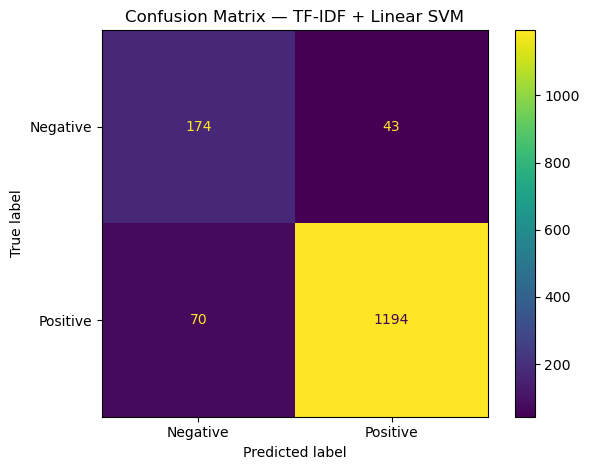

Saved to: C:\Users\Rafael Bantilan\OneDrive\Desktop\AI DATA\IE4483_MiniProject/results/figures/final_linear_svm_confusion_matrix.png


In [31]:
svm_model = clone(svm_search.best_estimator_)

start_time = time.time()

svm_model.fit(
    train_df["clean_reviews"],
    y_train
)

svm_training_time = time.time() - start_time

svm_train_pred = svm_model.predict(train_df["clean_reviews"])
svm_val_pred = svm_model.predict(val_df["clean_reviews"])

# No predict_proba, so use the decision score for ROC-AUC
svm_train_score = svm_model.decision_function(train_df["clean_reviews"])
svm_val_score = svm_model.decision_function(val_df["clean_reviews"])

svm_train_metrics = metric_dict(
    y_train,
    svm_train_pred,
    svm_train_score
)

svm_val_metrics = metric_dict(
    y_val,
    svm_val_pred,
    svm_val_score
)

svm_final_results = {
    "Model": "TF-IDF + Linear SVM",
    "Feature Format": "TF-IDF",
    "Training Accuracy": svm_train_metrics["Accuracy"],
    "Validation Accuracy": svm_val_metrics["Accuracy"],
    "Precision": svm_val_metrics["Precision"],
    "Recall": svm_val_metrics["Recall"],
    "F1": svm_val_metrics["F1"],
    "Macro F1": svm_val_metrics["Macro F1"],
    "Macro F1 Std": np.nan,  # deterministic
    "Negative Recall": svm_val_metrics["Negative Recall"],
    "ROC-AUC": svm_val_metrics["ROC-AUC"],
    "Training Time (s)": svm_training_time,
    "Seeds": 1
}

print(
    f"TF-IDF {svm_search.best_params_['tfidf__ngram_range']} + Linear SVM "
    f"(C={svm_search.best_params_['svm__C']}, "
    f"class_weight={svm_search.best_params_['svm__class_weight']}, "
    f"sublinear_tf={svm_search.best_params_['tfidf__sublinear_tf']})"
)
display(pd.DataFrame([svm_final_results]).round(4))

print("\nValidation classification report")
print(classification_report(y_val, svm_val_pred, digits=4))

plot_confusion_matrix(
    y_val,
    svm_val_pred,
    "TF-IDF + Linear SVM",
    "final_linear_svm_confusion_matrix.png"
)

joblib.dump(
    svm_model,
    f"{MODELS_DIR}/final_linear_svm_holdout_model.joblib"
)

pd.DataFrame({
    "review": val_df["reviews"].values,
    "actual": y_val,
    "predicted": svm_val_pred,
    "decision_score": svm_val_score
}).to_csv(
    f"{METRICS_DIR}/linear_svm_validation_predictions.csv",
    index=False
)


In [32]:
# Logistic Regression vs Linear SVM
def class_level_metrics(name, y_true, y_pred, score, train_time):
    cm = confusion_matrix(y_true, y_pred)
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro_F1": f1_score(y_true, y_pred, average="macro"),
        "Positive_F1": f1_score(y_true, y_pred),
        "Positive_Precision": precision_score(y_true, y_pred),
        "Positive_Recall": recall_score(y_true, y_pred),
        "Negative_F1": f1_score(y_true, y_pred, pos_label=0),
        "Negative_Precision": precision_score(y_true, y_pred, pos_label=0, zero_division=0),
        "Negative_Recall": recall_score(y_true, y_pred, pos_label=0),
        "ROC_AUC": roc_auc_score(y_true, score),
        "TN": cm[0, 0], "FP": cm[0, 1], "FN": cm[1, 0], "TP": cm[1, 1],
        "Wrong": int((y_true != y_pred).sum()),
        "Training_Time_s": train_time
    }

lr_best = lr_search.best_params_
lr_label = (
    f"Logistic Regression ({lr_best['tfidf__ngram_range']}, "
    f"{lr_best['tfidf__max_features'] or 'all'} features, "
    f"C={lr_best['lr__C']}, class_weight={lr_best['lr__class_weight']})"
)

svm_best = svm_search.best_params_
svm_label = (
    f"Linear SVM ({svm_best['tfidf__ngram_range']}, 10000 features, "
    f"C={svm_best['svm__C']}, class_weight={svm_best['svm__class_weight']})"
)

svm_vs_lr_df = pd.DataFrame([
    class_level_metrics(lr_label, y_val, lr_val_pred, lr_val_prob, lr_training_time),
    class_level_metrics(svm_label, y_val, svm_val_pred, svm_val_score, svm_training_time)
])

print("Holdout set (1,481 reviews) — Logistic Regression vs Linear SVM")
print("TN/FP/FN/TP use 0 = negative as the 'actual' row: FP = negative review predicted positive.")
display(svm_vs_lr_df.set_index("Model").T.round(4))

svm_vs_lr_df.to_csv(
    f"{METRICS_DIR}/svm_vs_logistic_regression.csv",
    index=False
)

print("Saved to:", f"{METRICS_DIR}/svm_vs_logistic_regression.csv")


Holdout set (1,481 reviews) — Logistic Regression vs Linear SVM
TN/FP/FN/TP use 0 = negative as the 'actual' row: FP = negative review predicted positive.


Model,"Logistic Regression ((1, 3), 40000 features, C=20.0, class_weight=balanced)","Linear SVM ((1, 2), 10000 features, C=0.5, class_weight=balanced)"
Accuracy,0.9278,0.9237
Macro_F1,0.8542,0.8548
Positive_F1,0.9578,0.9548
Positive_Precision,0.9559,0.9652
Positive_Recall,0.9597,0.9446
Negative_F1,0.7506,0.7549
Negative_Precision,0.7594,0.7131
Negative_Recall,0.7419,0.8018
ROC_AUC,0.9480,0.9479
TN,161.0000,174.0000


Saved to: C:\Users\Rafael Bantilan\OneDrive\Desktop\AI DATA\IE4483_MiniProject/results/metrics/svm_vs_logistic_regression.csv


## 9.3 What the Linear SVM learned

The largest positive and negative TF-IDF feature weights.


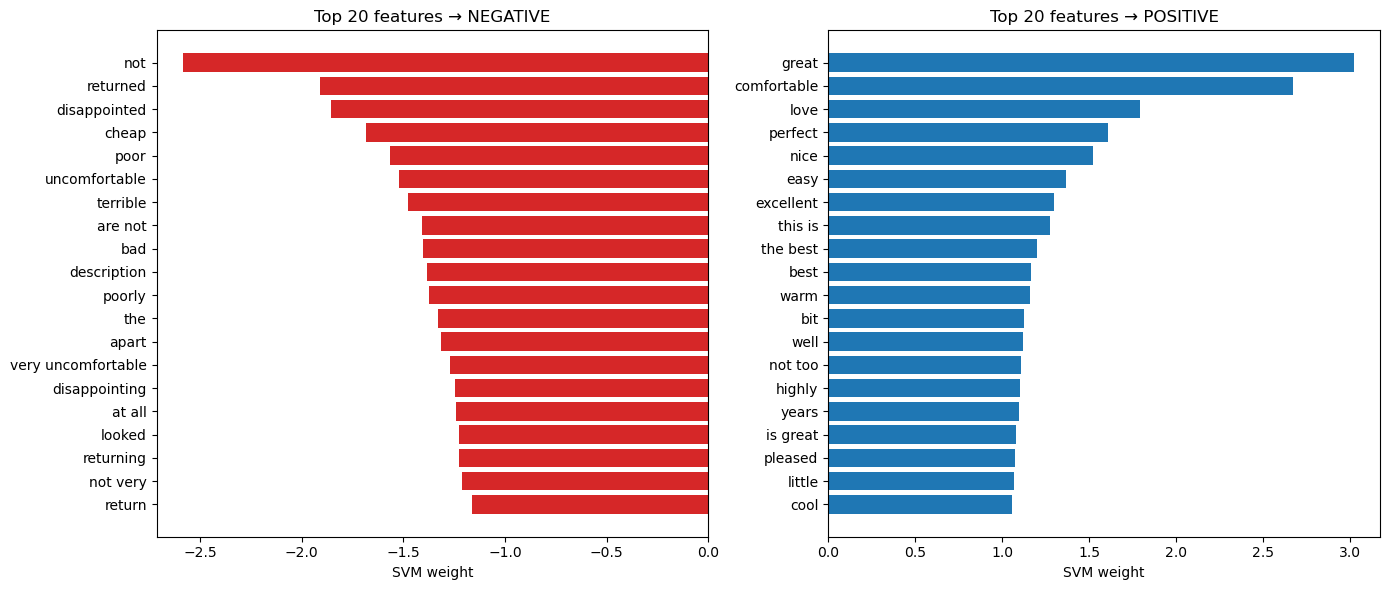

Saved to: C:\Users\Rafael Bantilan\OneDrive\Desktop\AI DATA\IE4483_MiniProject/results/figures/svm_top_features.png


In [33]:
feature_names = svm_model.named_steps["tfidf"].get_feature_names_out()
svm_weights = svm_model.named_steps["svm"].coef_.ravel()

svm_weight_df = pd.DataFrame({
    "feature": feature_names,
    "weight": svm_weights
}).sort_values("weight")

top_negative = svm_weight_df.head(20)
top_positive = svm_weight_df.tail(20).iloc[::-1]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].barh(top_negative["feature"][::-1], top_negative["weight"][::-1], color="tab:red")
axes[0].set_title("Top 20 features → NEGATIVE")
axes[0].set_xlabel("SVM weight")

axes[1].barh(top_positive["feature"][::-1], top_positive["weight"][::-1], color="tab:blue")
axes[1].set_title("Top 20 features → POSITIVE")
axes[1].set_xlabel("SVM weight")

plt.tight_layout()

figure_path = f"{FIGURES_DIR}/svm_top_features.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved to:", figure_path)

svm_weight_df.to_csv(
    f"{METRICS_DIR}/svm_feature_weights.csv",
    index=False
)

## 9.4 Holdout errors — Linear SVM vs Logistic Regression

Holdout reviews the SVM got wrong, sorted by how confident it was.


In [34]:
svm_val_analysis = pd.DataFrame({
    "review": val_df["reviews"].values,
    "actual": y_val,
    "svm_pred": svm_val_pred,
    "svm_score": svm_val_score,
    "lr_pred": lr_val_pred,
    "lr_prob_positive": lr_val_prob,
    "length_words": val_df["review_length_words"].values
})

svm_val_analysis["svm_correct"] = svm_val_analysis["actual"] == svm_val_analysis["svm_pred"]
svm_val_analysis["lr_correct"] = svm_val_analysis["actual"] == svm_val_analysis["lr_pred"]

print("Agreement between the two models on the validation set:")
display(pd.crosstab(
    svm_val_analysis["svm_correct"].map({True: "SVM correct", False: "SVM wrong"}),
    svm_val_analysis["lr_correct"].map({True: "LR correct", False: "LR wrong"})
))

svm_errors = svm_val_analysis[~svm_val_analysis["svm_correct"]].copy()
svm_errors["confidence"] = svm_errors["svm_score"].abs()

false_positives = svm_errors[svm_errors["actual"] == 0].sort_values("confidence", ascending=False)
false_negatives = svm_errors[svm_errors["actual"] == 1].sort_values("confidence", ascending=False)

pd.set_option("display.max_colwidth", 300)

print(f"\nFalse positives (negative review predicted positive): {len(false_positives)}")
display(false_positives[["review", "svm_score", "lr_pred", "length_words"]].head(8))

print(f"\nFalse negatives (positive review predicted negative): {len(false_negatives)}")
display(false_negatives[["review", "svm_score", "lr_pred", "length_words"]].head(8))

print("\nNegative reviews the SVM gets right but Logistic Regression misses (sample):")
display(
    svm_val_analysis[
        (svm_val_analysis["actual"] == 0) &
        svm_val_analysis["svm_correct"] &
        ~svm_val_analysis["lr_correct"]
    ][["review", "svm_score", "lr_prob_positive"]].head(5)
)

pd.reset_option("display.max_colwidth")

svm_errors_path = f"{ERROR_DIR}/svm_validation_errors.csv"
svm_errors.to_csv(svm_errors_path, index=False)
print("Saved all SVM validation errors to:", svm_errors_path)

Agreement between the two models on the validation set:


lr_correct,LR correct,LR wrong
svm_correct,,
SVM correct,1351,17
SVM wrong,23,90



False positives (negative review predicted positive): 43


,review,svm_score,lr_pred,length_words
374,Dilvered quickly in time for Christmas. Sweatshirt was great quality,1.584913,1,10
803,"My ""tween"" daughter loves these Saucony Jazz shoes.\nThey are comfortable and stylish.\nThis is her 3rd pair.\nI'm glad that I found them online.\nThey are both old-school and stylish",1.419612,1,31
954,"Hi. I wanted to get my grandsons each an Army outfit, cause Dad said they wanted 'army stuff"" (grandpa was an army retiree) He was telling me exactly what to get. What was army, and what wasnt. When he saw these, he says ""cool"" , when I told him the price, he says doubly cool! I am prou...",1.262111,1,90
968,"These slippers are typical of Daniel Green products, beautiful, comfortable and affordable.\nThank",1.056407,1,13
1129,The slipper seems to have some craftmenship. In my case they seem to run about a half size small. Who wants to wait for a pair of slippers to stretch? I wish I had known this in advance ... they look good in my closet though,1.014290,1,46
516,"They are adorable shoes, but I have some other flats from Soda that are more comfortable. I have wide feet though, so that might explain why I feel so cramped in them",0.941958,1,32
1127,"The Vibram soles leave black streaks all over the floors, and make it so I cannot wear them at work. I love Rockports in general, and these are comfortable and well made as expected, but they leave a trail of scuff marks",0.717326,1,42
1361,I still got a pantyline with this---strange and frustrating----\n:,0.691591,1,10



False negatives (positive review predicted negative): 70


,review,svm_score,lr_pred,length_words
706,"but the bag is not very deep so doesn't hold as much as I was hoping...also, even empty, the zipper is very difficult to operate. I wondered if security would be able to rezip it had they opened it",-1.102354,0,39
1265,"I bought this product because the description read ""12 Pack"", but I actually received a 2 pack",-0.906453,0,17
1046,"The item was what I expected however, It took them weeks to have the item shipped. I sent over emails to follow up and they never responded. Bad customer service.",-0.719096,0,30
356,"this hat really wasn't quite what i'd expected...i thought i was purchasing a winter-y sort of knit hat, and it turns out that the front fabric of the hat is actually quite thin, and the back of the hat is that trucker cap type of mesh material. i didn't even notice it in the picture at all, the...",-0.665341,0,97
282,"These were nice, lightweight budget jazz shoes; however, they do NOT fit the same as street shoes, despite what the description says. My daughter wears a 2.5 in street shoes, and I ordered her a 4 in the jazz bootie thinking there would be plenty of room for growth. WRONG! I have to return them ...",-0.614875,0,67
150,"Ordering online and not being able to try on clothing can be risky but it paid off with this purchase. I just wish it wasn't ""hand wash only"".",-0.579911,0,28
1156,I like the wallet. The quality was good but the wood gift box was a big disappointment. I expected the box to be fully enclosed but it wasn't and the wallet fell out of it,-0.569381,0,35
949,This shoe is so much better than the picture shown. The red is just perfect. The picture does not do it justice....and you just cant beat the price.,-0.548982,0,28



Negative reviews the SVM gets right but Logistic Regression misses (sample):


,review,svm_score,lr_prob_positive
159,"for $30, i guess i cant complain but this are not good looking or comfortable shoe",-0.021428,0.639495
288,These bras offer zero support. They would be good for someone who is young and firm enough to not need it:,-0.082749,0.660101
319,I bought these slippers as a present for my husband for Christmas. I can't return them because he wore them for a day. These slippers were so badly made that he is wearing his old slippers. The shape of the sole on the right foot is the same as the left. Don't waste your money,-0.369257,0.603134
370,"I wouldn't wear these socks for two reasons:\n\n1. They have a red stripe at the toe and I wanted to wear them with sandals.\n\n2. They have their brandname emblazoned in red on the side, also ridiculous looking with sandals.",-0.059288,0.521280
378,"I have to say I am rather disappointed with this item. Considering its price, I was expecting a firm control garment. It's not that it isn't well constructed and it is very comfortable, but it isn't anything approaching what I would call 'firm-control'. I don't think it would qualify for the tit...",-0.025412,0.626896


Saved all SVM validation errors to: C:\Users\Rafael Bantilan\OneDrive\Desktop\AI DATA\IE4483_MiniProject/results/error_analysis/svm_validation_errors.csv


# 10. LSTM

A bidirectional LSTM that reads each review in order. It uses the same internal split, tokeniser and vocabulary as
TextCNN (Section 8). `val_df` is only used once, in 10.5.


## 10.1 LSTM classifier

token IDs → embedding → packed (Bi)LSTM → final hidden states or max pooling → dropout → linear output.


In [35]:
%%requires_torch
class LSTMClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim,
        hidden_dim,
        num_layers,
        bidirectional,
        dropout,
        pooling="last"
    ):
        super().__init__()

        self.bidirectional = bool(bidirectional)
        self.pooling = pooling

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=PAD_IDX
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=self.bidirectional,
            # Dropout only applies between stacked layers
            dropout=dropout if num_layers > 1 else 0.0
        )

        self.dropout = nn.Dropout(dropout)

        n_directions = 2 if self.bidirectional else 1
        self.fc = nn.Linear(hidden_dim * n_directions, 1)

    def forward(self, x):
        # Real review lengths
        lengths = (x != PAD_IDX).sum(dim=1).clamp(min=1)

        embedded = self.embedding(x)

        packed = nn.utils.rnn.pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        packed_output, (h_n, _) = self.lstm(packed)

        if self.pooling == "max":
            # Max pooling over time
            output, _ = nn.utils.rnn.pad_packed_sequence(
                packed_output,
                batch_first=True,
                padding_value=float("-inf")
            )
            features = output.max(dim=1).values
        elif self.bidirectional:
            # Final forward and backward states
            features = torch.cat([h_n[-2], h_n[-1]], dim=1)
        else:
            features = h_n[-1]

        features = self.dropout(features)
        return self.fc(features).squeeze(1)

def build_lstm(config, vocab_size):
    return LSTMClassifier(
        vocab_size=vocab_size,
        embedding_dim=int(config["embedding_dim"]),
        hidden_dim=int(config["hidden_dim"]),
        num_layers=int(config["num_layers"]),
        bidirectional=bool(config["bidirectional"]),
        dropout=float(config["dropout"]),
        pooling=str(config["pooling"])
    )

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# Shape check
lstm_check_config = {
    "embedding_dim": 128,
    "hidden_dim": 128,
    "num_layers": 1,
    "bidirectional": True,
    "dropout": 0.3,
    "pooling": "last"
}

lstm_check_model = build_lstm(lstm_check_config, len(tune_word_to_idx)).to(device)
lstm_check_model.eval()

with torch.no_grad():
    lstm_check_logits = lstm_check_model(X_cnn_fit[:8].to(device))

print("Input batch :", tuple(X_cnn_fit[:8].shape), "(reviews x token ids)")
print("Output      :", tuple(lstm_check_logits.shape), "(one logit per review)")
print(f"Trainable parameters (E128 / H128 / 1-layer BiLSTM): {count_parameters(lstm_check_model):,}")

del lstm_check_model, lstm_check_logits


Input batch : (8, 200) (reviews x token ids)
Output      : (8,) (one logit per review)
Trainable parameters (E128 / H128 / 1-layer BiLSTM): 1,544,449


## 10.2 LSTM training functions

Same setup as the TextCNN functions in 8.4, with gradient clipping added.


In [36]:
%%requires_torch
LSTM_GRAD_CLIP = 1.0

@torch.no_grad()
def lstm_mean_loss(model, X, y, criterion, batch_size):
    model.eval()
    total_loss = 0.0

    for X_batch, y_batch in make_loader(X, y, batch_size=batch_size, shuffle=False):
        logits = model(X_batch.to(device))
        total_loss += criterion(logits, y_batch.to(device)).item() * len(X_batch)

    return total_loss / len(X)

def train_lstm_for_tuning(
    config,
    vocab_size,
    X_fit,
    y_fit,
    X_tune,
    y_tune,
    seed=SEED
):
    set_seed(seed)

    model = build_lstm(config, vocab_size).to(device)

    train_loader = make_loader(
        X_fit,
        y_fit,
        batch_size=int(config["batch_size"]),
        shuffle=True,
        seed=seed
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=float(config["learning_rate"])
    )

    criterion = make_criterion(config, y_fit)

    max_epochs = int(config["epochs"])
    patience = int(config.get("patience", 3))

    best_state = None
    best_macro_f1 = -np.inf
    best_accuracy = -np.inf
    best_epoch = 0
    patience_counter = 0
    history = []

    start_time = time.time()

    for epoch in range(1, max_epochs + 1):
        model.train()
        epoch_loss = 0.0

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            loss = criterion(model(X_batch), y_batch)
            loss.backward()

            # Clip gradients
            torch.nn.utils.clip_grad_norm_(model.parameters(), LSTM_GRAD_CLIP)

            optimizer.step()
            epoch_loss += loss.item() * len(X_batch)

        tune_metrics, _, _, _ = evaluate_cnn(
            model,
            X_tune,
            y_tune,
            int(config["batch_size"])
        )

        history.append({
            "Epoch": epoch,
            "Train Loss": epoch_loss / len(X_fit),
            "Tune Loss": lstm_mean_loss(
                model, X_tune, y_tune, criterion, int(config["batch_size"])
            ),
            "Tune Macro F1": tune_metrics["Macro F1"],
            "Tune Accuracy": tune_metrics["Accuracy"]
        })

        current_macro = tune_metrics["Macro F1"]
        current_accuracy = tune_metrics["Accuracy"]

        improved = (
            current_macro > best_macro_f1 + 1e-12
            or (
                abs(current_macro - best_macro_f1) <= 1e-12
                and current_accuracy > best_accuracy
            )
        )

        if improved:
            best_macro_f1 = current_macro
            best_accuracy = current_accuracy
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= patience:
            break

    training_time = time.time() - start_time

    model.load_state_dict(best_state)

    best_metrics, _, _, _ = evaluate_cnn(
        model,
        X_tune,
        y_tune,
        int(config["batch_size"])
    )

    best_metrics["Best Epoch"] = best_epoch
    best_metrics["Training Time (s)"] = training_time

    return model, best_metrics, pd.DataFrame(history)

def tune_lstm_multi_seed(
    config,
    vocab_size,
    X_fit,
    y_fit,
    X_tune,
    y_tune,
    seeds=TUNING_SEEDS
):
    # Average the metrics over the seeds
    seed_rows = []

    for seed in seeds:
        model, metrics, _ = train_lstm_for_tuning(
            config,
            vocab_size,
            X_fit,
            y_fit,
            X_tune,
            y_tune,
            seed=seed
        )
        seed_rows.append(metrics)

        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    seed_df = pd.DataFrame(seed_rows)

    summary = seed_df.mean(numeric_only=True).to_dict()
    summary["Macro F1 Std"] = seed_df["Macro F1"].std()
    summary["Best Epoch"] = int(round(seed_df["Best Epoch"].mean()))
    summary["Best Epochs per Seed"] = str(seed_df["Best Epoch"].tolist())
    summary["Training Time (s)"] = seed_df["Training Time (s)"].sum()

    return summary

def train_lstm_fixed_epochs(
    config,
    vocab_size,
    X_train,
    y_train_tensor,
    epochs,
    seed=SEED
):
    set_seed(seed)

    model = build_lstm(config, vocab_size).to(device)

    train_loader = make_loader(
        X_train,
        y_train_tensor,
        batch_size=int(config["batch_size"]),
        shuffle=True,
        seed=seed
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=float(config["learning_rate"])
    )

    criterion = make_criterion(config, y_train_tensor)

    start_time = time.time()

    for _ in range(int(epochs)):
        model.train()

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            loss = criterion(model(X_batch), y_batch)
            loss.backward()

            torch.nn.utils.clip_grad_norm_(model.parameters(), LSTM_GRAD_CLIP)

            optimizer.step()

    training_time = time.time() - start_time

    return model, training_time


## 10.3 LSTM hyperparameter experiment

One parameter is changed at a time on the internal tuning split. Each candidate uses 3 seeds, and the mean macro-F1 decides.


In [37]:
%%requires_torch
baseline_lstm_config = {
    "class_weight": None,
    "embedding_dim": 128,
    "hidden_dim": 128,
    "num_layers": 1,
    "bidirectional": True,
    "dropout": 0.3,
    "learning_rate": 0.001,
    "batch_size": 64,
    "epochs": 15,  # cap only
    "patience": 3,
    "pooling": "last"
}

lstm_tuning_plan = [
    ("class_weight", [None, "balanced"]),
    ("bidirectional", [False, True]),
    ("hidden_dim", [64, 128, 256]),
    ("num_layers", [1, 2]),
    ("embedding_dim", [128, 256]),
    ("dropout", [0.2, 0.3, 0.5]),
    ("learning_rate", [0.0005, 0.001, 0.002]),
    ("pooling", ["last", "max"])
]

baseline_lstm_metrics = tune_lstm_multi_seed(
    baseline_lstm_config,
    vocab_size=len(tune_word_to_idx),
    X_fit=X_cnn_fit,
    y_fit=y_cnn_fit,
    X_tune=X_cnn_tune,
    y_tune=y_cnn_tune
)

print(f"Baseline LSTM — internal tuning split (mean of {len(TUNING_SEEDS)} seeds)")
display(pd.DataFrame([{**baseline_lstm_config, **baseline_lstm_metrics}]).round(4))

best_lstm_config = baseline_lstm_config.copy()
lstm_experiment_results = []
selected_lstm_epochs = None

lstm_tuning_start = time.time()

for parameter, values in lstm_tuning_plan:
    stage_results = []

    for value in tqdm(
        values,
        desc=f"Tuning {parameter}",
        unit="config"
    ):
        config = best_lstm_config.copy()
        config[parameter] = value

        metrics = tune_lstm_multi_seed(
            config,
            vocab_size=len(tune_word_to_idx),
            X_fit=X_cnn_fit,
            y_fit=y_cnn_fit,
            X_tune=X_cnn_tune,
            y_tune=y_cnn_tune
        )

        result = {
            "Parameter Tuned": parameter,
            **config,
            **metrics
        }

        stage_results.append(result)
        lstm_experiment_results.append(result)

    stage_df = pd.DataFrame(stage_results).sort_values(
        ["Macro F1", "Accuracy"],
        ascending=[False, False]
    ).reset_index(drop=True)

    selected_value = stage_df.loc[0, parameter]

    if parameter == "class_weight":
        selected_value = None if pd.isna(selected_value) else str(selected_value)
    elif parameter == "bidirectional":
        selected_value = bool(selected_value)
    elif parameter == "pooling":
        selected_value = str(selected_value)
    elif parameter in {"hidden_dim", "num_layers", "embedding_dim"}:
        selected_value = int(selected_value)
    else:
        selected_value = float(selected_value)

    best_lstm_config[parameter] = selected_value
    selected_lstm_epochs = int(stage_df.loc[0, "Best Epoch"])

    print(
        f"Selected {parameter}: {selected_value} | "
        f"mean tune macro-F1={stage_df.loc[0, 'Macro F1']:.4f} "
        f"± {stage_df.loc[0, 'Macro F1 Std']:.4f} | "
        f"mean accuracy={stage_df.loc[0, 'Accuracy']:.4f} | "
        f"best epochs {stage_df.loc[0, 'Best Epochs per Seed']}"
    )

lstm_tuning_time = time.time() - lstm_tuning_start

lstm_experiment_results_df = pd.DataFrame(lstm_experiment_results)

lstm_experiment_path = (
    f"{EXPERIMENTS_DIR}/"
    "lstm_internal_tuning_experiments.csv"
)

lstm_experiment_results_df.to_csv(
    lstm_experiment_path,
    index=False
)

LSTM_MODEL_NAME = "BiLSTM" if best_lstm_config["bidirectional"] else "LSTM"

print(f"\nTuning finished in {lstm_tuning_time / 60:.1f} minutes")
print(f"\nFinal {LSTM_MODEL_NAME} configuration:")
for key, value in best_lstm_config.items():
    print(f"  {key}: {value}")

print("Selected fixed epoch count:", selected_lstm_epochs)

# Warn if the epoch cap was reached
best_epochs = eval(stage_df.loc[0, "Best Epochs per Seed"])
if max(best_epochs) >= int(best_lstm_config["epochs"]):
    print(f"NOTE: a seed's best epoch reached the cap of {best_lstm_config['epochs']} epochs.")

# Note if a value is at the edge of its range
for parameter, values in lstm_tuning_plan:
    if len(values) >= 3 and best_lstm_config[parameter] in (values[0], values[-1]):
        print(f"NOTE: selected {parameter} = {best_lstm_config[parameter]} is at the edge of the values tried {values}.")

lstm_selected_model = build_lstm(best_lstm_config, len(final_word_to_idx))
print(f"Trainable parameters (selected configuration): {count_parameters(lstm_selected_model):,}")
del lstm_selected_model

print("Saved:", lstm_experiment_path)


Baseline LSTM — internal tuning split (mean of 3 seeds)


,class_weight,embedding_dim,hidden_dim,num_layers,bidirectional,dropout,learning_rate,batch_size,epochs,patience,...,Precision,Recall,F1,Macro F1,Negative Recall,ROC-AUC,Best Epoch,Training Time (s),Macro F1 Std,Best Epochs per Seed
0,None,128,128,1,True,0.3,0.001,64,15,3,...,0.9317,0.938,0.9347,0.7719,0.5973,0.8974,8,40.005,0.016,"[10, 6, 7]"


Tuning class_weight:   0%|          | 0/2 [00:00<?, ?config/s]

Selected class_weight: balanced | mean tune macro-F1=0.7747 ± 0.0167 | mean accuracy=0.8846 | best epochs [10, 5, 7]


Tuning bidirectional:   0%|          | 0/2 [00:00<?, ?config/s]

Selected bidirectional: True | mean tune macro-F1=0.7747 ± 0.0167 | mean accuracy=0.8846 | best epochs [10, 5, 7]


... (8 outputs left out)

Tuning learning_rate:   0%|          | 0/3 [00:00<?, ?config/s]

Selected learning_rate: 0.001 | mean tune macro-F1=0.7846 ± 0.0081 | mean accuracy=0.8933 | best epochs [14, 15, 9]


Tuning pooling:   0%|          | 0/2 [00:00<?, ?config/s]

Selected pooling: max | mean tune macro-F1=0.7964 ± 0.0118 | mean accuracy=0.8882 | best epochs [6, 5, 11]

Tuning finished in 13.5 minutes

Final BiLSTM configuration:
  class_weight: balanced
  embedding_dim: 256
  hidden_dim: 128
  num_layers: 1
  bidirectional: True
  dropout: 0.5
  learning_rate: 0.001
  batch_size: 64
  epochs: 15
  patience: 3
  pooling: max
Selected fixed epoch count: 7
NOTE: selected dropout = 0.5 is at the edge of the values tried [0.2, 0.3, 0.5].
Trainable parameters (selected configuration): 2,955,521
Saved: C:\Users\Rafael Bantilan\OneDrive\Desktop\AI DATA\IE4483_MiniProject/results/experiments/lstm_internal_tuning_experiments.csv


## 10.4 Training curves (selected configuration)

Loss and macro-F1 per epoch for the selected configuration (seed 42).


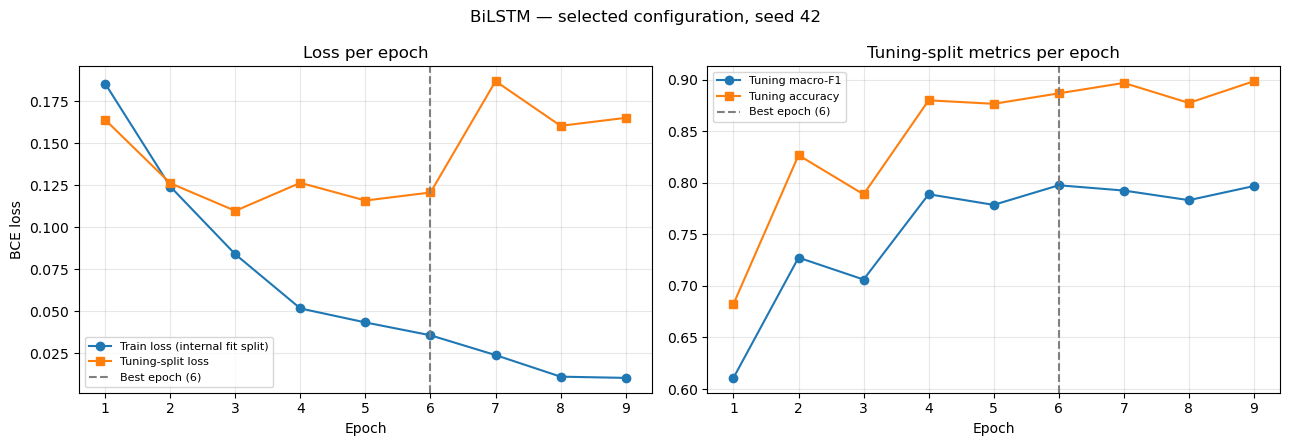

,Epoch,Train Loss,Tune Loss,Tune Macro F1,Tune Accuracy
0,1,0.1854,0.1639,0.6108,0.6824
1,2,0.1242,0.1262,0.7275,0.8269
2,3,0.0839,0.1097,0.7062,0.7889
3,4,0.0516,0.1264,0.7889,0.8801
4,5,0.0433,0.1158,0.7786,0.8767
5,6,0.0357,0.1206,0.7976,0.8868
6,7,0.0239,0.1869,0.7925,0.8970
7,8,0.0110,0.1603,0.7832,0.8775
8,9,0.0103,0.1650,0.7969,0.8986


Saved to: C:\Users\Rafael Bantilan\OneDrive\Desktop\AI DATA\IE4483_MiniProject/results/figures/lstm_training_curves.png


In [38]:
%%requires_torch
lstm_curve_model, lstm_curve_metrics, lstm_history = train_lstm_for_tuning(
    best_lstm_config,
    vocab_size=len(tune_word_to_idx),
    X_fit=X_cnn_fit,
    y_fit=y_cnn_fit,
    X_tune=X_cnn_tune,
    y_tune=y_cnn_tune,
    seed=SEED
)

del lstm_curve_model
if torch.cuda.is_available():
    torch.cuda.empty_cache()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(lstm_history["Epoch"], lstm_history["Train Loss"], "o-", label="Train loss (internal fit split)")
axes[0].plot(lstm_history["Epoch"], lstm_history["Tune Loss"], "s-", label="Tuning-split loss")
axes[0].set_title("Loss per epoch")
axes[0].set_ylabel("BCE loss")

axes[1].plot(lstm_history["Epoch"], lstm_history["Tune Macro F1"], "o-", label="Tuning macro-F1")
axes[1].plot(lstm_history["Epoch"], lstm_history["Tune Accuracy"], "s-", label="Tuning accuracy")
axes[1].set_title("Tuning-split metrics per epoch")

for ax in axes:
    ax.axvline(
        lstm_curve_metrics["Best Epoch"],
        linestyle="--",
        color="grey",
        label=f"Best epoch ({lstm_curve_metrics['Best Epoch']})"
    )
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

fig.suptitle(f"{LSTM_MODEL_NAME} — selected configuration, seed {SEED}")
plt.tight_layout()

figure_path = f"{FIGURES_DIR}/lstm_training_curves.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

display(lstm_history.round(4))
print("Saved to:", figure_path)


## 10.5 Final LSTM — holdout evaluation over 5 seeds

The selected configuration is trained on the full `train_df` with 5 seeds and evaluated once on `val_df`.


BiLSTM — final holdout, one row per seed


,Seed,Training Accuracy,Accuracy,Precision,Recall,F1,Macro F1,Negative Recall,ROC-AUC,Training Time (s)
0,42,0.9951,0.9183,0.9468,0.9581,0.9524,0.8318,0.6866,0.9262,12.7580
1,43,0.9856,0.9149,0.9452,0.9557,0.9504,0.8252,0.6774,0.9333,12.2695
2,44,0.9816,0.8886,0.9553,0.9122,0.9332,0.7986,0.7512,0.9289,12.3468
3,45,0.9818,0.8940,0.9548,0.9193,0.9367,0.8052,0.7465,0.9293,12.2589
4,46,0.9779,0.9001,0.9658,0.9153,0.9399,0.8219,0.8111,0.9315,12.2531



Mean ± std over 5 seeds:
  Accuracy: 0.9032 ± 0.0130
  Macro F1: 0.8165 ± 0.0141
  Negative Recall: 0.7346 ± 0.0544
  ROC-AUC: 0.9298 ± 0.0027
Trainable parameters: 2,955,521

Validation classification report (seed 42 model)
              precision    recall  f1-score   support

           0     0.7376    0.6866    0.7112       217
           1     0.9468    0.9581    0.9524      1264

    accuracy                         0.9183      1481
   macro avg     0.8422    0.8224    0.8318      1481
weighted avg     0.9162    0.9183    0.9171      1481



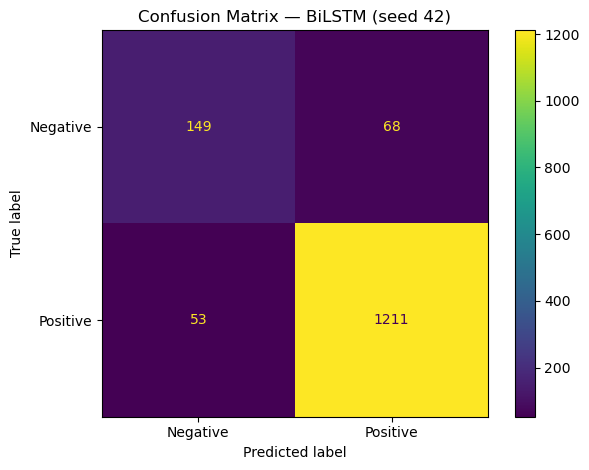

Saved to: C:\Users\Rafael Bantilan\OneDrive\Desktop\AI DATA\IE4483_MiniProject/results/figures/final_lstm_confusion_matrix.png


In [39]:
%%requires_torch
lstm_seed_rows = []

for seed in FINAL_SEEDS:
    model, train_time = train_lstm_fixed_epochs(
        config=best_lstm_config,
        vocab_size=len(final_word_to_idx),
        X_train=X_train_cnn_final,
        y_train_tensor=y_train_cnn_final,
        epochs=selected_lstm_epochs,
        seed=seed
    )

    train_metrics, _, _, _ = evaluate_cnn(
        model,
        X_train_cnn_final,
        y_train_cnn_final,
        int(best_lstm_config["batch_size"])
    )

    val_metrics, _, val_prob, val_pred = evaluate_cnn(
        model,
        X_val_cnn_final,
        y_val_cnn_final,
        int(best_lstm_config["batch_size"])
    )

    lstm_seed_rows.append({
        "Seed": seed,
        "Training Accuracy": train_metrics["Accuracy"],
        **val_metrics,
        "Training Time (s)": train_time
    })

    if seed == SEED:
        lstm_final_model = model
        lstm_training_time = train_time
        lstm_val_metrics = val_metrics
        lstm_val_prob = val_prob
        lstm_val_pred = val_pred
    else:
        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

lstm_seed_df = pd.DataFrame(lstm_seed_rows)

print(f"{LSTM_MODEL_NAME} — final holdout, one row per seed")
display(lstm_seed_df.round(4))

lstm_seed_df.to_csv(
    f"{METRICS_DIR}/lstm_holdout_by_seed.csv",
    index=False
)

lstm_mean = lstm_seed_df.drop(columns="Seed").mean()
lstm_std = lstm_seed_df.drop(columns="Seed").std()

lstm_final_results = {
    "Model": LSTM_MODEL_NAME,
    "Feature Format": "Token Sequence + Learned Embedding",
    "Training Accuracy": lstm_mean["Training Accuracy"],
    "Validation Accuracy": lstm_mean["Accuracy"],
    "Precision": lstm_mean["Precision"],
    "Recall": lstm_mean["Recall"],
    "F1": lstm_mean["F1"],
    "Macro F1": lstm_mean["Macro F1"],
    "Macro F1 Std": lstm_std["Macro F1"],
    "Negative Recall": lstm_mean["Negative Recall"],
    "ROC-AUC": lstm_mean["ROC-AUC"],
    "Training Time (s)": lstm_mean["Training Time (s)"],
    "Seeds": len(FINAL_SEEDS)
}

print(f"\nMean ± std over {len(FINAL_SEEDS)} seeds:")
for metric in ["Accuracy", "Macro F1", "Negative Recall", "ROC-AUC"]:
    print(f"  {metric}: {lstm_mean[metric]:.4f} ± {lstm_std[metric]:.4f}")

print(f"Trainable parameters: {count_parameters(lstm_final_model):,}")

print(f"\nValidation classification report (seed {SEED} model)")
print(classification_report(y_val, lstm_val_pred, digits=4))

plot_confusion_matrix(
    y_val,
    lstm_val_pred,
    f"{LSTM_MODEL_NAME} (seed {SEED})",
    "final_lstm_confusion_matrix.png"
)

torch.save({
    "model_state_dict": lstm_final_model.state_dict(),
    "config": best_lstm_config,
    "selected_epochs": selected_lstm_epochs,
    "seed": SEED,
    "word_to_idx": final_word_to_idx,
    "max_sequence_length": CNN_MAX_LEN
}, f"{MODELS_DIR}/final_lstm_holdout_model.pt")


## 10.6 Holdout errors — LSTM vs Linear SVM

Compares the seed-42 LSTM with the Linear SVM on the holdout.


In [40]:
%%requires_torch
lstm_vs_svm_df = pd.DataFrame({
    "review": val_df["reviews"].values,
    "actual": y_val,
    "lstm_pred": lstm_val_pred,
    "lstm_prob_positive": lstm_val_prob,
    "svm_pred": svm_val_pred,
    "svm_score": svm_val_score,
    "length_words": val_df["review_length_words"].values
})

lstm_vs_svm_df["lstm_correct"] = lstm_vs_svm_df["actual"] == lstm_vs_svm_df["lstm_pred"]
lstm_vs_svm_df["svm_correct"] = lstm_vs_svm_df["actual"] == lstm_vs_svm_df["svm_pred"]
lstm_vs_svm_df["has_contrast_word"] = lstm_vs_svm_df["review"].str.contains(
    r"\b(?:but|however|although|though)\b",
    case=False,
    regex=True
)

print(f"Agreement between {LSTM_MODEL_NAME} (seed {SEED}) and the Linear SVM on the holdout:")
display(pd.crosstab(
    lstm_vs_svm_df["lstm_correct"].map({True: "LSTM correct", False: "LSTM wrong"}),
    lstm_vs_svm_df["svm_correct"].map({True: "SVM correct", False: "SVM wrong"})
))

lstm_only = lstm_vs_svm_df[lstm_vs_svm_df["lstm_correct"] & ~lstm_vs_svm_df["svm_correct"]]
svm_only = lstm_vs_svm_df[~lstm_vs_svm_df["lstm_correct"] & lstm_vs_svm_df["svm_correct"]]

print(f"\nShare of reviews containing a contrast word:")
print(f"  all holdout reviews          : {lstm_vs_svm_df['has_contrast_word'].mean() * 100:.1f}%")
print(f"  LSTM right, SVM wrong ({len(lstm_only):3d}) : {lstm_only['has_contrast_word'].mean() * 100:.1f}%")
print(f"  SVM right, LSTM wrong ({len(svm_only):3d}) : {svm_only['has_contrast_word'].mean() * 100:.1f}%")

pd.set_option("display.max_colwidth", 300)

print("\nLSTM right, SVM wrong — reviews with contrast words (sample):")
display(
    lstm_only[lstm_only["has_contrast_word"]]
    [["review", "actual", "lstm_prob_positive", "svm_score"]]
    .head(5)
)

print("\nSVM right, LSTM wrong (sample):")
display(
    svm_only[["review", "actual", "lstm_prob_positive", "svm_score"]]
    .head(5)
)

pd.reset_option("display.max_colwidth")

lstm_errors_path = f"{ERROR_DIR}/lstm_vs_svm_holdout_errors.csv"
lstm_vs_svm_df[
    ~lstm_vs_svm_df["lstm_correct"] | ~lstm_vs_svm_df["svm_correct"]
].to_csv(lstm_errors_path, index=False)

print("Saved:", lstm_errors_path)


Agreement between BiLSTM (seed 42) and the Linear SVM on the holdout:


svm_correct,SVM correct,SVM wrong
lstm_correct,,
LSTM correct,1310,50
LSTM wrong,58,63



Share of reviews containing a contrast word:
  all holdout reviews          : 37.7%
  LSTM right, SVM wrong ( 50) : 60.0%
  SVM right, LSTM wrong ( 58) : 51.7%

LSTM right, SVM wrong — reviews with contrast words (sample):


,review,actual,lstm_prob_positive,svm_score
16,I like the design simplicity of this shoe but don't use it for jogging or running as you will feel uncomfortable. I guess it is made for walking,1,0.542596,-0.248071
193,"This short is minimalistic. Just what you need if you are doing Yoga. Grips the leg, does not show what you do not what to show. I use black underpants under them, as they are a bit too minimalistic without. I think they are a bit overpriced, but I have not found as good a short for less (low de...",1,0.806435,-0.222016
237,I already knew it would be a pretty bad idea to buy a wig online but i didn't expect they would pack it up as badly as they did. It was totally mangled and mashed when I got it. They get four stars though because the wig itself is amazingly good once you restyle it yourself. Though I'm still hav...,1,0.668301,-0.173042
245,"I recently purchased these shoes for a night out on Valentine's Day with my boyfriend. I had a great experience with this product and service.\nThe shoes themselves were completely wrapped up in their box. Because of the delicate beading on the shoes, I was afraid that poor packaging may cause...",1,0.730444,-0.212754
282,"These were nice, lightweight budget jazz shoes; however, they do NOT fit the same as street shoes, despite what the description says. My daughter wears a 2.5 in street shoes, and I ordered her a 4 in the jazz bootie thinking there would be plenty of room for growth. WRONG! I have to return them ...",1,0.955746,-0.614875



SVM right, LSTM wrong (sample):


,review,actual,lstm_prob_positive,svm_score
34,"For the money I spent on this bra it should be a better bra all around. It gives a classic ""torpedo"" shape to the breasts, does not offer any lift, and is pretty much unwearable.",0,0.574816,-0.173844
67,This is the only Haynes T-shirt that does not bunch at the back of the neck. It is light and drapes well. But it is too light for printing.,0,0.794719,-0.438890
74,"This is a very sexy outfit. My one complaint is that the ""3 piece set"" is actually two pieces; the top being one while the skirt is attached to the g-string. This doesn't take too much away from the outfit, but it would have been nice to have been given a more accurate description of the produ...",1,0.214554,0.470521
151,"I was really looking forward to recieving these ""MEMORY FOAM"" slippers. When they arrived I was EXTREMELY disappointed to discover that they only had a ""RUBBER"" sole with terry cloth. (The terry cloth and color were beautiful and the size 11 narrow was great on the fit.) I hope the factory just...",0,0.861620,-0.343169
159,"for $30, i guess i cant complain but this are not good looking or comfortable shoe",0,0.920067,-0.021428


Saved: C:\Users\Rafael Bantilan\OneDrive\Desktop\AI DATA\IE4483_MiniProject/results/error_analysis/lstm_vs_svm_holdout_errors.csv


# 11. Multilayer Perceptron (MLP)

MLP is a feedforward neural network that learns nonlinear relationships between input features and output classes.


In [41]:
from sklearn.feature_extraction.text import TfidfVectorizer

# train/val here are the internal fit/tuning split

# Convert text into numerical features
mlp_tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    lowercase=False
)

# Fit only on training reviews to avoid data leakage
X_train_mlp = mlp_tfidf.fit_transform(cnn_fit_df["clean_reviews"])
X_val_mlp = mlp_tfidf.transform(cnn_tune_df["clean_reviews"])

y_train_mlp = cnn_fit_df["sentiments"].values
y_val_mlp = cnn_tune_df["sentiments"].values

print("Training shape:", X_train_mlp.shape)
print("Validation shape:", X_val_mlp.shape)


Training shape: (4736, 5000)
Validation shape: (1184, 5000)


In [42]:
%%requires_torch
# Pytorch Libraries



import torch
import torch.nn as nn
import numpy as np

# Set random seed for reproducibility
torch.manual_seed(SEED)
np.random.seed(SEED)

# Define MLP neural network
class MLP(nn.Module):
    def __init__(self, input_dim=5000):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)

# Initialize model
model = MLP(input_dim=X_train_mlp.shape[1]).to(device)

# Display architecture
print(model)


MLP(
  (network): Sequential(
    (0): Linear(in_features=5000, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [43]:
%%requires_torch
import torch.optim as optim

# Convert sparse TF-IDF matrices to dense tensors
X_train_tensor = torch.tensor(
    X_train_mlp.toarray(), dtype=torch.float32
).to(device)

X_val_tensor = torch.tensor(
    X_val_mlp.toarray(), dtype=torch.float32
).to(device)

# Convert labels to float tensors
y_train_tensor = torch.tensor(
    y_train_mlp, dtype=torch.float32
).reshape(-1, 1).to(device)

y_val_tensor = torch.tensor(
    y_val_mlp, dtype=torch.float32
).reshape(-1, 1).to(device)


# Give negative reviews greater importance
num_positive = (y_train_mlp == 1).sum()
num_negative = (y_train_mlp == 0).sum()

pos_weight = torch.tensor(
    [num_negative / num_positive],
    dtype=torch.float32,
    device=device
)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

# Adam optimizer
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("Training tensor:", X_train_tensor.shape)
print("Training labels:", y_train_tensor.shape)
print("Validation tensor:", X_val_tensor.shape)
print("Validation labels:", y_val_tensor.shape)


Training tensor: torch.Size([4736, 5000])
Training labels: torch.Size([4736, 1])
Validation tensor: torch.Size([1184, 5000])
Validation labels: torch.Size([1184, 1])


## 11.1 Train the MLP

Start with 20 epochs and track training loss, validation loss and validation accuracy *(validation here = the internal tuning split)*.

In [44]:
%%requires_torch
from sklearn.metrics import accuracy_score
import copy

epochs = 20

train_losses = []
val_losses = []
val_accuracies = []

best_val_loss = float("inf")
best_model_state = None

for epoch in range(epochs):

    # Training phase
    model.train()

    optimizer.zero_grad()

    outputs = model(X_train_tensor)
    loss = criterion(outputs, y_train_tensor)

    loss.backward()
    optimizer.step()

    train_losses.append(loss.item())

    # Validation phase
    model.eval()

    with torch.no_grad():
        val_outputs = model(X_val_tensor)
        val_loss = criterion(val_outputs, y_val_tensor)

        val_probs = torch.sigmoid(val_outputs)
        val_preds = (val_probs >= 0.5).int().cpu().numpy()

        val_acc = accuracy_score(
            y_val_mlp, val_preds.ravel()
        )

    val_losses.append(val_loss.item())
    val_accuracies.append(val_acc)

    # Save best model based on validation loss
    if val_loss.item() < best_val_loss:
        best_val_loss = val_loss.item()
        best_model_state = copy.deepcopy(model.state_dict())

    print(
        f"Epoch {epoch+1:02d}/{epochs} | "
        f"Train Loss: {loss.item():.4f} | "
        f"Val Loss: {val_loss.item():.4f} | "
        f"Val Accuracy: {val_acc:.4f}"
    )

# Restore best model
model.load_state_dict(best_model_state)

print("\nBest validation loss:", round(best_val_loss, 4))


Epoch 01/20 | Train Loss: 0.2027 | Val Loss: 0.2025 | Val Accuracy: 0.1461
Epoch 02/20 | Train Loss: 0.2024 | Val Loss: 0.2023 | Val Accuracy: 0.1461
Epoch 03/20 | Train Loss: 0.2021 | Val Loss: 0.2020 | Val Accuracy: 0.1461
Epoch 04/20 | Train Loss: 0.2016 | Val Loss: 0.2016 | Val Accuracy: 0.1461
Epoch 05/20 | Train Loss: 0.2010 | Val Loss: 0.2011 | Val Accuracy: 0.1461
Epoch 06/20 | Train Loss: 0.2003 | Val Loss: 0.2005 | Val Accuracy: 0.1546
Epoch 07/20 | Train Loss: 0.1995 | Val Loss: 0.1998 | Val Accuracy: 0.3150
Epoch 08/20 | Train Loss: 0.1986 | Val Loss: 0.1991 | Val Accuracy: 0.5405
Epoch 09/20 | Train Loss: 0.1975 | Val Loss: 0.1983 | Val Accuracy: 0.6757
Epoch 10/20 | Train Loss: 0.1963 | Val Loss: 0.1973 | Val Accuracy: 0.7627
Epoch 11/20 | Train Loss: 0.1950 | Val Loss: 0.1963 | Val Accuracy: 0.8074
Epoch 12/20 | Train Loss: 0.1935 | Val Loss: 0.1952 | Val Accuracy: 0.8438
Epoch 13/20 | Train Loss: 0.1918 | Val Loss: 0.1939 | Val Accuracy: 0.8590
Epoch 14/20 | Train Loss:

## 11.2 Check Class Imbalance

Accuracy plateaus at 0.8535 at first train


In [45]:
%%requires_torch
print("Training distribution:")
print(cnn_fit_df["sentiments"].value_counts(normalize=True))

print("\nValidation distribution:")
print(cnn_tune_df["sentiments"].value_counts(normalize=True))

print("\nPredicted distribution:")
model.eval()
with torch.no_grad():
    predictions = (
        torch.sigmoid(model(X_val_tensor)) >= 0.5
    ).int().cpu().numpy().ravel()

print(np.unique(predictions, return_counts=True))


Training distribution:
sentiments
1    0.853885
0    0.146115
Name: proportion, dtype: float64

Validation distribution:
sentiments
1    0.853885
0    0.146115
Name: proportion, dtype: float64

Predicted distribution:
(array([0, 1]), array([210, 974], dtype=int64))


## 11.3 Evaluate Classification Performance

Measure Precision, recall, F1-score

In [46]:
%%requires_torch
from sklearn.metrics import classification_report, confusion_matrix

model.eval()

with torch.no_grad():
    logits = model(X_val_tensor)
    probabilities = torch.sigmoid(logits)
    predictions = (probabilities >= 0.5).int().cpu().numpy().ravel()

print(classification_report(
    y_val_mlp,
    predictions,
    target_names=["Negative", "Positive"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_val_mlp, predictions))


              precision    recall  f1-score   support

    Negative       0.63      0.77      0.69       173
    Positive       0.96      0.92      0.94      1011

    accuracy                           0.90      1184
   macro avg       0.80      0.85      0.82      1184
weighted avg       0.91      0.90      0.91      1184

Confusion Matrix:
[[133  40]
 [ 77 934]]


## 11.4 Tuning Hyperparameters

Define a configurable MLP to change hidden layers and dropout rate.

In [47]:
%%requires_torch
class TunableMLP(nn.Module):
    def __init__(self, input_dim, hidden1, hidden2, dropout):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden1),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(hidden1, hidden2),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(hidden2, 1)
        )

    def forward(self, x):
        return self.network(x)


## 11.5 Run the Tuning Loop


In [48]:
%%requires_torch
from itertools import product
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import copy

# Hyperparameters
hidden_sizes = [(64, 32), (128, 64), (256, 128)]
learning_rates = [0.0001, 0.001]
dropout_rates = [0.0, 0.3]
feature_counts = [5000, 10000, 20000]
tuning_seeds = TUNING_SEEDS
max_epochs = 60

results = []
best_f1 = -1
best_config = None

tfidf_by_size = {}
for max_features in feature_counts:
    size_tfidf = TfidfVectorizer(max_features=max_features, ngram_range=(1, 2), lowercase=False)
    tfidf_by_size[max_features] = (
        torch.tensor(size_tfidf.fit_transform(cnn_fit_df["clean_reviews"]).toarray(), dtype=torch.float32),
        torch.tensor(size_tfidf.transform(cnn_tune_df["clean_reviews"]).toarray(), dtype=torch.float32).to(device)
    )

y_fit_labels = torch.tensor(y_train_mlp, dtype=torch.float32).reshape(-1, 1)

# Same class-weighting approach as before
num_positive = (y_train_mlp == 1).sum()
num_negative = (y_train_mlp == 0).sum()

pos_weight = torch.tensor(
    [num_negative / num_positive],
    dtype=torch.float32,
    device=device
)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

# Generate all 36 combinations
for max_features, hidden, lr, dropout in product(
    feature_counts, hidden_sizes, learning_rates, dropout_rates
):
    X_fit_features, X_tune_features = tfidf_by_size[max_features]
    seed_runs = []

    for seed in tuning_seeds:
        torch.manual_seed(seed)

        # Initialize a fresh model
        tuning_model = TunableMLP(
            input_dim=X_fit_features.shape[1],
            hidden1=hidden[0],
            hidden2=hidden[1],
            dropout=dropout
        ).to(device)

        optimizer = optim.Adam(tuning_model.parameters(), lr=lr)

        # Mini-batch training
        dataset = torch.utils.data.TensorDataset(
            X_fit_features, y_fit_labels
        )

        generator = torch.Generator().manual_seed(seed)

        loader = torch.utils.data.DataLoader(
            dataset,
            batch_size=128,
            shuffle=True,
            generator=generator
        )

        run_best_f1 = -1
        run_best_epoch = 0
        run_best_state = None
        patience = 5
        no_improvement = 0

        for epoch in range(max_epochs):
            tuning_model.train()

            for xb, yb in loader:
                xb, yb = xb.to(device), yb.to(device)
                optimizer.zero_grad()

                outputs = tuning_model(xb)
                loss = criterion(outputs, yb)

                loss.backward()
                optimizer.step()

            # Validation (internal tuning split)
            tuning_model.eval()

            with torch.no_grad():
                logits = tuning_model(X_tune_features)
                predictions = (
                    torch.sigmoid(logits) >= 0.5
                ).int().cpu().numpy().ravel()

            macro_f1 = f1_score(
                y_val_mlp,
                predictions,
                average="macro"
            )

            # Save the best epoch for this configuration
            if macro_f1 > run_best_f1 + 1e-4:
                run_best_f1 = macro_f1
                run_best_epoch = epoch + 1
                run_best_state = copy.deepcopy(
                    tuning_model.state_dict()
                )
                no_improvement = 0
            else:
                no_improvement += 1

            if no_improvement >= patience:
                break

        # Restore best epoch
        tuning_model.load_state_dict(run_best_state)
        tuning_model.eval()

        with torch.no_grad():
            predictions = (
                torch.sigmoid(tuning_model(X_tune_features)) >= 0.5
            ).int().cpu().numpy().ravel()

        accuracy = accuracy_score(y_val_mlp, predictions)

        seed_runs.append({
            "Best Epoch": run_best_epoch,
            "Accuracy": accuracy,
            "Macro F1": run_best_f1
        })

    seed_df = pd.DataFrame(seed_runs)

    results.append({
        "Max Features": max_features,
        "Hidden Layers": str(hidden),
        "Learning Rate": lr,
        "Dropout": dropout,
        "Best Epoch": int(round(seed_df["Best Epoch"].mean())),
        "Best Epochs per Seed": str(seed_df["Best Epoch"].tolist()),
        "Accuracy": seed_df["Accuracy"].mean(),
        "Macro F1": seed_df["Macro F1"].mean(),
        "Macro F1 Std": seed_df["Macro F1"].std()
    })

    print(
        f"Features={max_features}, Hidden={hidden}, LR={lr}, Dropout={dropout} "
        f"| Accuracy={results[-1]['Accuracy']:.4f} "
        f"| Macro F1={results[-1]['Macro F1']:.4f} ± {results[-1]['Macro F1 Std']:.4f}"
    )

    if results[-1]["Macro F1"] > best_f1:
        best_f1 = results[-1]["Macro F1"]
        best_config = (hidden, lr, dropout)
        best_max_features = max_features
        best_epochs = results[-1]["Best Epoch"]

del tfidf_by_size
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Display sorted results
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    "Macro F1", ascending=False
).reset_index(drop=True)

display(results_df)

print("\nBest configuration:", best_config)
print("Best TF-IDF size:", best_max_features)
print("Selected epoch count:", best_epochs)

if max(eval(results_df.loc[0, "Best Epochs per Seed"])) >= max_epochs:
    print(f"NOTE: a seed's best epoch reached the cap of {max_epochs} epochs.")
if best_max_features in (feature_counts[0], feature_counts[-1]):
    print(f"NOTE: the selected TF-IDF size {best_max_features} is at the edge of the values tried {feature_counts}.")
if best_config[0] in (hidden_sizes[0], hidden_sizes[-1]):
    print(f"NOTE: the selected hidden sizes {best_config[0]} are at the edge of the values tried {hidden_sizes}.")


Features=5000, Hidden=(64, 32), LR=0.0001, Dropout=0.0 | Accuracy=0.9141 | Macro F1=0.8392 ± 0.0018


Features=5000, Hidden=(64, 32), LR=0.0001, Dropout=0.3 | Accuracy=0.9105 | Macro F1=0.8364 ± 0.0017


Features=5000, Hidden=(64, 32), LR=0.001, Dropout=0.0 | Accuracy=0.9108 | Macro F1=0.8382 ± 0.0038


Features=5000, Hidden=(64, 32), LR=0.001, Dropout=0.3 | Accuracy=0.9147 | Macro F1=0.8387 ± 0.0057


Features=5000, Hidden=(128, 64), LR=0.0001, Dropout=0.0 | Accuracy=0.9144 | Macro F1=0.8383 ± 0.0019


Features=5000, Hidden=(128, 64), LR=0.0001, Dropout=0.3 | Accuracy=0.9147 | Macro F1=0.8388 ± 0.0021


... (28 outputs left out)

Features=20000, Hidden=(256, 128), LR=0.001, Dropout=0.0 | Accuracy=0.9043 | Macro F1=0.8267 ± 0.0125


Features=20000, Hidden=(256, 128), LR=0.001, Dropout=0.3 | Accuracy=0.9009 | Macro F1=0.8265 ± 0.0036


,Max Features,Hidden Layers,Learning Rate,Dropout,Best Epoch,Best Epochs per Seed,Accuracy,Macro F1,Macro F1 Std
0,10000,"(128, 64)",0.0001,0.0,17,"[15, 19, 17]",0.920045,0.848603,0.000311
1,10000,"(256, 128)",0.0001,0.0,12,"[11, 12, 12]",0.920608,0.847417,0.002374
2,20000,"(64, 32)",0.0001,0.3,18,"[16, 11, 28]",0.921453,0.847302,0.003446
3,20000,"(128, 64)",0.0001,0.3,14,"[16, 16, 11]",0.920608,0.847201,0.001955
4,20000,"(256, 128)",0.0001,0.0,9,"[7, 9, 11]",0.921453,0.847069,0.002131
5,20000,"(128, 64)",0.0001,0.0,14,"[15, 15, 13]",0.920045,0.846562,0.001415
6,20000,"(256, 128)",0.0001,0.3,8,"[8, 6, 11]",0.921734,0.845856,0.002097
7,10000,"(64, 32)",0.0010,0.0,4,"[3, 4, 4]",0.916385,0.845409,0.005862
8,10000,"(256, 128)",0.0001,0.3,11,"[11, 12, 11]",0.917793,0.844784,0.001399
9,20000,"(64, 32)",0.0010,0.3,4,"[4, 3, 4]",0.915822,0.844602,0.005801



Best configuration: ((128, 64), 0.0001, 0.0)
Best TF-IDF size: 10000
Selected epoch count: 17


## 11.6 Evaluating the best MLP model

Evaluate the tuned model with the highest macro F1-score.


TF-IDF + MLP — holdout val_df, one row per seed


,Seed,Training Accuracy,Accuracy,Precision,Recall,F1,Macro F1,Negative Recall,ROC-AUC,Training Time (s)
0,42,0.9858,0.9196,0.9576,0.9478,0.9527,0.8432,0.7558,0.9462,2.1656
1,43,0.9855,0.9196,0.9584,0.9470,0.9526,0.8438,0.7604,0.9470,2.1263
2,44,0.9860,0.9230,0.9571,0.9525,0.9548,0.8479,0.7512,0.9467,2.1953
3,45,0.9853,0.9217,0.9577,0.9502,0.9539,0.8463,0.7558,0.9466,2.0955
4,46,0.9853,0.9217,0.9585,0.9494,0.9539,0.8469,0.7604,0.9467,1.9258



Mean ± std over 5 seeds:
  Accuracy: 0.9211 ± 0.0015
  Macro F1: 0.8456 ± 0.0020
  Negative Recall: 0.7567 ± 0.0039
  ROC-AUC: 0.9466 ± 0.0003

Classification Report:
              precision    recall  f1-score   support

    Negative       0.71      0.76      0.73       217
    Positive       0.96      0.95      0.95      1264

    accuracy                           0.92      1481
   macro avg       0.84      0.85      0.84      1481
weighted avg       0.92      0.92      0.92      1481

Accuracy: 0.9196488858879136
Macro F1: 0.8432323286233383


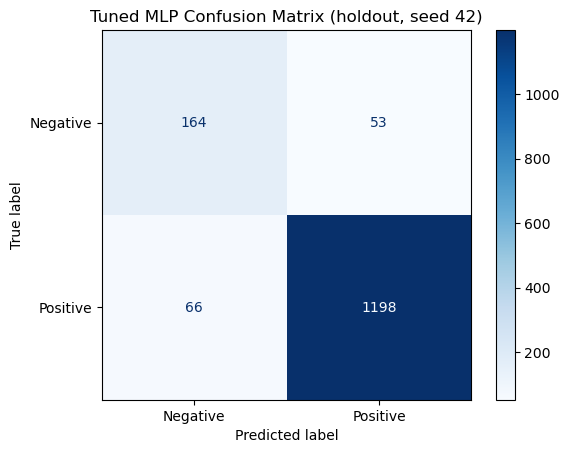

In [49]:
%%requires_torch
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader

# Rebuild the best MLP configuration
hidden, lr, dropout = best_config

holdout_tfidf = TfidfVectorizer(max_features=best_max_features, ngram_range=(1, 2), lowercase=False)
X_holdout_train = torch.tensor(holdout_tfidf.fit_transform(train_df["clean_reviews"]).toarray(), dtype=torch.float32)
X_holdout_val = torch.tensor(holdout_tfidf.transform(val_df["clean_reviews"]).toarray(), dtype=torch.float32).to(device)
y_holdout_train = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)

holdout_pos_weight = torch.tensor(
    [(y_train == 0).sum() / (y_train == 1).sum()],
    dtype=torch.float32,
    device=device
)
holdout_criterion = nn.BCEWithLogitsLoss(pos_weight=holdout_pos_weight)

holdout_rows = []

for seed in FINAL_SEEDS:
    torch.manual_seed(seed)

    best_mlp = TunableMLP(
        input_dim=X_holdout_train.shape[1],
        hidden1=hidden[0],
        hidden2=hidden[1],
        dropout=dropout
    ).to(device)

    optimizer = optim.Adam(best_mlp.parameters(), lr=lr)

    loader = DataLoader(
        TensorDataset(X_holdout_train, y_holdout_train),
        batch_size=128,
        shuffle=True,
        generator=torch.Generator().manual_seed(seed)
    )

    start_time = time.time()

    for epoch in range(best_epochs):
        best_mlp.train()

        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = holdout_criterion(best_mlp(xb), yb)
            loss.backward()
            optimizer.step()

    seed_training_time = time.time() - start_time

    best_mlp.eval()

    # Predict validation reviews
    with torch.no_grad():
        logits = best_mlp(X_holdout_val)
        probabilities = torch.sigmoid(logits)
        predictions = (probabilities >= 0.5).int().cpu().numpy().ravel()

        train_predictions = (
            torch.sigmoid(best_mlp(X_holdout_train.to(device))) >= 0.5
        ).int().cpu().numpy().ravel()

    seed_probabilities = probabilities.cpu().numpy().ravel()

    holdout_rows.append({
        "Seed": seed,
        "Training Accuracy": accuracy_score(y_train, train_predictions),
        **metric_dict(y_val, predictions, seed_probabilities),
        "Training Time (s)": seed_training_time
    })

    if seed == SEED:
        mlp_final_model = best_mlp
        mlp_val_pred = predictions
        mlp_val_prob = seed_probabilities

holdout_df = pd.DataFrame(holdout_rows)
print("TF-IDF + MLP — holdout val_df, one row per seed")
display(holdout_df.round(4))

holdout_df.to_csv(f"{METRICS_DIR}/mlp_holdout_by_seed.csv", index=False)

holdout_mean = holdout_df.drop(columns="Seed").mean()
holdout_std = holdout_df.drop(columns="Seed").std()

print(f"\nMean ± std over {len(FINAL_SEEDS)} seeds:")
for metric in ["Accuracy", "Macro F1", "Negative Recall", "ROC-AUC"]:
    print(f"  {metric}: {holdout_mean[metric]:.4f} ± {holdout_std[metric]:.4f}")

MLP_MODEL_NAME = "TF-IDF + MLP"

mlp_final_results = {
    "Model": MLP_MODEL_NAME,
    "Feature Format": "TF-IDF",
    "Training Accuracy": holdout_mean["Training Accuracy"],
    "Validation Accuracy": holdout_mean["Accuracy"],
    "Precision": holdout_mean["Precision"],
    "Recall": holdout_mean["Recall"],
    "F1": holdout_mean["F1"],
    "Macro F1": holdout_mean["Macro F1"],
    "Macro F1 Std": holdout_std["Macro F1"],
    "Negative Recall": holdout_mean["Negative Recall"],
    "ROC-AUC": holdout_mean["ROC-AUC"],
    "Training Time (s)": holdout_mean["Training Time (s)"],
    "Seeds": len(FINAL_SEEDS)
}

best_mlp = mlp_final_model
predictions = mlp_val_pred
y_val_mlp = y_val

# Classification metrics
print("\nClassification Report:")
print(classification_report(
    y_val_mlp,
    predictions,
    target_names=["Negative", "Positive"]
))

print("Accuracy:", accuracy_score(y_val_mlp, predictions))
print("Macro F1:", f1_score(
    y_val_mlp, predictions, average="macro"
))

# Confusion matrix
cm = confusion_matrix(y_val_mlp, predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot(cmap="Blues")
plt.title("Tuned MLP Confusion Matrix (holdout, seed 42)")
plt.show()

del X_holdout_train


In [50]:
%%requires_torch
# Save all 12 hyperparameter experiments
results_df.to_csv(f"{EXPERIMENTS_DIR}/MLP_tuning_results.csv", index=False)


from sklearn.metrics import classification_report

# Save precision, recall and F1-scores
report = classification_report(
    y_val_mlp,
    predictions,
    target_names=["Negative", "Positive"],
    output_dict=True
)

pd.DataFrame(report).transpose().to_csv(
    f"{METRICS_DIR}/MLP_evaluation_results.csv"
)

# Save confusion matrix figure
disp.figure_.savefig(
    f"{FIGURES_DIR}/MLP_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)


from sklearn.metrics import classification_report

# Save precision, recall and F1-scores
report = classification_report(
    y_val_mlp,
    predictions,
    target_names=["Negative", "Positive"],
    output_dict=True
)


torch.save({
    "model_state_dict": best_mlp.state_dict(),
    "best_config": best_config,
    "best_epoch": int(results_df.iloc[0]["Best Epoch"]),
    "max_features": best_max_features
}, f"{MODELS_DIR}/MLP_best_model.pth")


## 11.7 Final MLP Model

Prepare the full train dataset

In [51]:
%%requires_torch
# Combine training and validation data
full_train_df = pd.concat(
    [train_df, val_df],
    ignore_index=True
)

# Fit TF-IDF on all labelled reviews
final_tfidf = TfidfVectorizer(
    max_features=best_max_features,
    ngram_range=(1, 2),
    lowercase=False
)

X_full = final_tfidf.fit_transform(
    full_train_df["clean_reviews"]
)

y_full = full_train_df["sentiments"].values

# Convert to PyTorch tensors
X_full_tensor = torch.tensor(
    X_full.toarray(), dtype=torch.float32
)

y_full_tensor = torch.tensor(
    y_full, dtype=torch.float32
).reshape(-1, 1)

print("Training features:", X_full_tensor.shape)
print("Training labels:", y_full_tensor.shape)


Training features: torch.Size([7401, 10000])
Training labels: torch.Size([7401, 1])


## 11.8 Train Final MLP with best pytorch model

In [52]:
%%requires_torch
from torch.utils.data import TensorDataset, DataLoader

# Set random seed
torch.manual_seed(SEED)
np.random.seed(SEED)

# Initialize final MLP
final_model = TunableMLP(
    input_dim=X_full_tensor.shape[1],
    hidden1=best_config[0][0],
    hidden2=best_config[0][1],
    dropout=best_config[2]
).to(device)

# Handle class imbalance
num_positive = (y_full == 1).sum()
num_negative = (y_full == 0).sum()

pos_weight = torch.tensor(
    [num_negative / num_positive],
    dtype=torch.float32,
    device=device
)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

optimizer = optim.Adam(
    final_model.parameters(),
    lr=best_config[1]
)

# Create mini-batches
full_dataset = TensorDataset(
    X_full_tensor,
    y_full_tensor
)

generator = torch.Generator().manual_seed(SEED)

full_loader = DataLoader(
    full_dataset,
    batch_size=128,
    shuffle=True,
    generator=generator
)

# Train for the selected number of epochs
final_train_losses = []

for epoch in range(best_epochs):
    final_model.train()
    running_loss = 0.0

    for xb, yb in full_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()

        outputs = final_model(xb)
        loss = criterion(outputs, yb)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * xb.size(0)

    avg_loss = running_loss / len(full_dataset)
    final_train_losses.append(avg_loss)

    print(
        f"Epoch {epoch+1:02d}/{best_epochs} | "
        f"Training Loss: {avg_loss:.4f}"
    )

print("\nFinal MLP training complete!")


Epoch 01/17 | Training Loss: 0.2027


Epoch 02/17 | Training Loss: 0.1997


Epoch 03/17 | Training Loss: 0.1917
Epoch 04/17 | Training Loss: 0.1780


Epoch 05/17 | Training Loss: 0.1584
Epoch 06/17 | Training Loss: 0.1340


Epoch 07/17 | Training Loss: 0.1087
Epoch 08/17 | Training Loss: 0.0863


Epoch 09/17 | Training Loss: 0.0685
Epoch 10/17 | Training Loss: 0.0549


Epoch 11/17 | Training Loss: 0.0446
Epoch 12/17 | Training Loss: 0.0369


Epoch 13/17 | Training Loss: 0.0309
Epoch 14/17 | Training Loss: 0.0262


Epoch 15/17 | Training Loss: 0.0224
Epoch 16/17 | Training Loss: 0.0193


Epoch 17/17 | Training Loss: 0.0168

Final MLP training complete!


In [53]:
%%requires_torch
import json
import pandas as pd
import torch

# Convert reviews using the final TF-IDF vectorizer
X_test = final_tfidf.transform(test_df["clean_reviews"])

X_test_tensor = torch.tensor(
    X_test.toarray(), dtype=torch.float32
).to(device)

# Generate predictions
final_model.eval()

with torch.no_grad():
    logits = final_model(X_test_tensor)
    probabilities = torch.sigmoid(logits)
    test_predictions = (probabilities >= 0.5).int().cpu().numpy().ravel()

print("Total test predictions:", len(test_predictions))
print("Predicted sentiment distribution:")
print(pd.Series(test_predictions).value_counts())

mlp_test_predictions = test_predictions
mlp_test_probabilities = probabilities.cpu().numpy().ravel()


Total test predictions: 1851
Predicted sentiment distribution:
1    1577
0     274
Name: count, dtype: int64


In [54]:
%%requires_torch
# Check test dataset structure
print(test_df.columns.tolist())
print(test_df.head(3))

# Check number of predictions
print("Predictions:", len(test_predictions))


['reviews', 'clean_reviews']
                                             reviews  \
0  I bought 2 sleepers.  sleeper had holes in the...   
1  I dare say these are just about the sexiest th...   
2  everything about the transaction (price, deliv...   

                                       clean_reviews  
0  i bought 2 sleepers. sleeper had holes in the ...  
1  i dare say these are just about the sexiest th...  
2  everything about the transaction (price, deliv...  
Predictions: 1851


In [55]:
%%requires_torch
# Create submission file
mlp_submission_preview = pd.DataFrame({
    "reviews": test_df["reviews"].values,
    "predictions": test_predictions
})

# Verify output
print(mlp_submission_preview.head())
print("Shape:", mlp_submission_preview.shape)


                                             reviews  predictions
0  I bought 2 sleepers.  sleeper had holes in the...            0
1  I dare say these are just about the sexiest th...            1
2  everything about the transaction (price, deliv...            1
3  Not bad for just a shirt.  Very durable, and m...            1
4  These are truly wrinkle free and longer than t...            1
Shape: (1851, 2)


# 12. Final Model Comparison

All candidate models below were tuned **without using `val_df`**.  
The table therefore compares them on the same untouched final holdout.

- Primary ranking: validation macro-F1
- Tie-breaker: validation accuracy
- Training accuracy is shown as a diagnostic for overfitting.
- TextCNN, LSTM and MLP rows are **means over 5 seeds** (`Macro F1 Std` shows the seed-to-seed spread); Logistic Regression and the Linear SVM are deterministic, so they have a single run.
- Test accuracy is unavailable because `test.json` has no labels.


In [56]:
candidate_results = [
    lr_final_results,
    svm_final_results
]

# Only when PyTorch is available
if TORCH_AVAILABLE:
    candidate_results += [
        cnn_final_results,
        multikernel_final_results,
        lstm_final_results,
        mlp_final_results
    ]

model_comparison_df = pd.DataFrame(
    candidate_results
).sort_values(
    ["Macro F1", "Validation Accuracy"],
    ascending=[False, False]
).reset_index(drop=True)

display(model_comparison_df.round(4))

selected_model_name = model_comparison_df.loc[0, "Model"]

print("=" * 70)
print("FINAL MODEL SELECTION")
print("=" * 70)
print("Selected model:", selected_model_name)
print(
    "Training Accuracy:",
    f"{model_comparison_df.loc[0, 'Training Accuracy']:.4f}"
)
print(
    "Final Holdout Accuracy:",
    f"{model_comparison_df.loc[0, 'Validation Accuracy']:.4f}"
)
print(
    "Final Holdout Macro F1:",
    f"{model_comparison_df.loc[0, 'Macro F1']:.4f}"
)
print("Test Accuracy: unavailable — test.json has no ground-truth labels.")

comparison_path = (
    f"{METRICS_DIR}/"
    "final_model_comparison.csv"
)

model_comparison_df.to_csv(
    comparison_path,
    index=False
)

print("Saved:", comparison_path)


,Model,Feature Format,Training Accuracy,Validation Accuracy,Precision,Recall,F1,Macro F1,Macro F1 Std,Negative Recall,ROC-AUC,Training Time (s),Seeds
0,TF-IDF + Linear SVM,TF-IDF,0.9878,0.9237,0.9652,0.9446,0.9548,0.8548,NaN,0.8018,0.9479,0.8244,1
1,TF-IDF + Logistic Regression,TF-IDF,0.9998,0.9278,0.9559,0.9597,0.9578,0.8542,NaN,0.7419,0.9480,2.2565,1
2,TextCNN,Token Sequence + Learned Embedding,0.9956,0.9219,0.9583,0.9500,0.9541,0.8470,0.0089,0.7585,0.9415,2.1527,5
3,TF-IDF + MLP,TF-IDF,0.9856,0.9211,0.9579,0.9494,0.9536,0.8456,0.0020,0.7567,0.9466,2.1017,5
4,Multi-Kernel TextCNN,Token Sequence + Learned Embedding,0.9989,0.9175,0.9504,0.9533,0.9517,0.8332,0.0148,0.7088,0.9367,3.4695,5
5,BiLSTM,Token Sequence + Learned Embedding,0.9844,0.9032,0.9536,0.9321,0.9425,0.8165,0.0141,0.7346,0.9298,12.3773,5


FINAL MODEL SELECTION
Selected model: TF-IDF + Linear SVM
Training Accuracy: 0.9878
Final Holdout Accuracy: 0.9237
Final Holdout Macro F1: 0.8548
Test Accuracy: unavailable — test.json has no ground-truth labels.
Saved: C:\Users\Rafael Bantilan\OneDrive\Desktop\AI DATA\IE4483_MiniProject/results/metrics/final_model_comparison.csv


# 13. Error Analysis on the Labelled Holdout

Because the official test set has no labels, correct/incorrect cases are identified from the final holdout set.


In [57]:
if selected_model_name == "TF-IDF + Logistic Regression":
    selected_val_pred = lr_val_pred
    selected_val_prob = lr_val_prob

elif selected_model_name == "TF-IDF + Linear SVM":
    selected_val_pred = svm_val_pred
    # Sigmoid of the SVM score (not a real probability)
    selected_val_prob = 1 / (1 + np.exp(-svm_val_score))

elif selected_model_name == "TextCNN":
    selected_val_pred = cnn_val_pred
    selected_val_prob = cnn_val_prob

elif selected_model_name == "Multi-Kernel TextCNN":
    selected_val_pred = multi_val_pred
    selected_val_prob = multi_val_prob

elif TORCH_AVAILABLE and selected_model_name == lstm_final_results["Model"]:
    selected_val_pred = lstm_val_pred
    selected_val_prob = lstm_val_prob

elif TORCH_AVAILABLE and selected_model_name == mlp_final_results["Model"]:
    selected_val_pred = mlp_val_pred
    selected_val_prob = mlp_val_prob

else:
    raise ValueError(
        f"No validation predictions connected for {selected_model_name}"
    )

error_analysis_df = pd.DataFrame({
    "review": val_df["reviews"].values,
    "actual": y_val,
    "predicted": selected_val_pred,
    "probability_positive_or_score": selected_val_prob
})

error_analysis_df["correct"] = (
    error_analysis_df["actual"] ==
    error_analysis_df["predicted"]
)

error_analysis_df["confidence"] = np.where(
    error_analysis_df["predicted"] == 1,
    error_analysis_df["probability_positive_or_score"],
    1 - error_analysis_df["probability_positive_or_score"]
)

error_path = (
    f"{ERROR_DIR}/"
    "selected_model_validation_error_analysis.csv"
)

error_analysis_df.to_csv(
    error_path,
    index=False
)

print("Selected model:", selected_model_name)
print("Correct predictions:", int(error_analysis_df["correct"].sum()))
print("Incorrect predictions:", int((~error_analysis_df["correct"]).sum()))
print("Saved:", error_path)

print("\nExample correct cases:")
display(
    error_analysis_df[
        error_analysis_df["correct"]
    ].head(2)
)

print("\nExample incorrect cases:")
display(
    error_analysis_df[
        ~error_analysis_df["correct"]
    ].head(2)
)


Selected model: TF-IDF + Linear SVM
Correct predictions: 1368
Incorrect predictions: 113
Saved: C:\Users\Rafael Bantilan\OneDrive\Desktop\AI DATA\IE4483_MiniProject/results/error_analysis/selected_model_validation_error_analysis.csv

Example correct cases:


,review,actual,predicted,probability_positive_or_score,correct,confidence
0,I love this bag! The quality of the canvas an...,1,1,0.685360,True,0.685360
1,Great product at a great price!! Fast shippin...,1,1,0.813957,True,0.813957



Example incorrect cases:


,review,actual,predicted,probability_positive_or_score,correct,confidence
16,I like the design simplicity of this shoe but ...,1,0,0.438298,False,0.561702
72,My daughter absolutely loved the wallet. I per...,1,0,0.418108,False,0.581892


# 14. Feature Representation and Resource Comparison

TF-IDF produces sparse bag-of-n-gram vectors for Logistic Regression and the Linear SVM; the MLP uses the same kind of TF-IDF vector (converted to a dense tensor) as input to non-linear hidden layers.  
TextCNN uses ordered token sequences and learns dense embeddings and convolution filters.  
The LSTM reads the same token sequences in order with a recurrent memory (embeddings + gated hidden state).

The final comparison table contains the measured accuracy and training-time evidence needed for the report discussion.


In [58]:
resource_comparison_df = model_comparison_df[
    [
        "Model",
        "Feature Format",
        "Training Accuracy",
        "Validation Accuracy",
        "F1",
        "Macro F1",
        "Training Time (s)"
    ]
].copy()

display(resource_comparison_df.round(4))


,Model,Feature Format,Training Accuracy,Validation Accuracy,F1,Macro F1,Training Time (s)
0,TF-IDF + Linear SVM,TF-IDF,0.9878,0.9237,0.9548,0.8548,0.8244
1,TF-IDF + Logistic Regression,TF-IDF,0.9998,0.9278,0.9578,0.8542,2.2565
2,TextCNN,Token Sequence + Learned Embedding,0.9956,0.9219,0.9541,0.8470,2.1527
3,TF-IDF + MLP,TF-IDF,0.9856,0.9211,0.9536,0.8456,2.1017
4,Multi-Kernel TextCNN,Token Sequence + Learned Embedding,0.9989,0.9175,0.9517,0.8332,3.4695
5,BiLSTM,Token Sequence + Learned Embedding,0.9844,0.9032,0.9425,0.8165,12.3773


# 15. Final Test Prediction

After the final holdout comparison:
1. settings are frozen;
2. each candidate is optionally re-fitted on **all labelled reviews** (`df`);
3. separate candidate test predictions are saved for checking;
4. the official `submission.csv` uses the model selected from the untouched final holdout.

The test set remains unlabelled, so prediction counts can be reported but test accuracy cannot.


In [59]:
# 15.1 Refit frozen candidates on all labelled data

# Logistic Regression
lr_all_model = clone(lr_search.best_estimator_)

start_time = time.time()

lr_all_model.fit(
    df["clean_reviews"],
    df["sentiments"].values
)

lr_all_fit_time = time.time() - start_time

lr_test_predictions = lr_all_model.predict(
    test_df["clean_reviews"]
).astype(int)

lr_test_probabilities = lr_all_model.predict_proba(
    test_df["clean_reviews"]
)[:, 1]

# Linear SVM
svm_all_model = clone(svm_search.best_estimator_)

start_time = time.time()

svm_all_model.fit(
    df["clean_reviews"],
    df["sentiments"].values
)

svm_all_fit_time = time.time() - start_time

svm_test_predictions = svm_all_model.predict(
    test_df["clean_reviews"]
).astype(int)

# Sigmoid of the SVM score (not a real probability)
svm_test_probabilities = 1 / (1 + np.exp(
    -svm_all_model.decision_function(test_df["clean_reviews"])
))

# Compare with the train_df-only SVM
svm_agreement = (
    svm_test_predictions == svm_model.predict(test_df["clean_reviews"])
).mean()

print(f"Linear SVM: agreement with the train_df-only model on test = {svm_agreement * 100:.2f}%")
print("Logistic Regression and Linear SVM refitted on all labelled data.")


Linear SVM: agreement with the train_df-only model on test = 97.46%
Logistic Regression and Linear SVM refitted on all labelled data.


In [60]:
%%requires_torch
# 15.1 (continued) Refit the TextCNN candidates on all labelled data

# CNN vocabulary from all labelled data
all_word_to_idx = build_vocab(
    df["clean_reviews"]
)

X_all_cnn = encode_series(
    df["clean_reviews"],
    all_word_to_idx
)

X_test_cnn_all = encode_series(
    test_df["clean_reviews"],
    all_word_to_idx
)

y_all_cnn = torch.tensor(
    df["sentiments"].values,
    dtype=torch.float32
)

# Single-kernel TextCNN
cnn_all_model, cnn_all_fit_time = train_cnn_fixed_epochs(
    config=best_cnn_config,
    vocab_size=len(all_word_to_idx),
    X_train=X_all_cnn,
    y_train_tensor=y_all_cnn,
    epochs=selected_cnn_epochs,
    multi_kernel=False
)

cnn_test_predictions, cnn_test_probabilities = predict_cnn_unlabeled(
    cnn_all_model,
    X_test_cnn_all,
    int(best_cnn_config["batch_size"])
)

# Multi-kernel TextCNN
multi_all_model, multi_all_fit_time = train_cnn_fixed_epochs(
    config=best_multikernel_config,
    vocab_size=len(all_word_to_idx),
    X_train=X_all_cnn,
    y_train_tensor=y_all_cnn,
    epochs=selected_multikernel_epochs,
    multi_kernel=True
)

multi_test_predictions, multi_test_probabilities = predict_cnn_unlabeled(
    multi_all_model,
    X_test_cnn_all,
    int(best_multikernel_config["batch_size"])
)

# LSTM
lstm_all_model, lstm_all_fit_time = train_lstm_fixed_epochs(
    config=best_lstm_config,
    vocab_size=len(all_word_to_idx),
    X_train=X_all_cnn,
    y_train_tensor=y_all_cnn,
    epochs=selected_lstm_epochs
)

lstm_test_predictions, lstm_test_probabilities = predict_cnn_unlabeled(
    lstm_all_model,
    X_test_cnn_all,
    int(best_lstm_config["batch_size"])
)

print("TextCNN and LSTM candidates have generated test predictions.")
print("Test accuracy cannot be calculated because test labels are hidden.")


TextCNN and LSTM candidates have generated test predictions.
Test accuracy cannot be calculated because test labels are hidden.


In [61]:
# 15.2 Save candidate prediction files

candidate_test_outputs = {
    "TF-IDF + Logistic Regression": (
        lr_test_predictions,
        lr_test_probabilities,
        "logistic_regression_test_predictions.csv"
    ),
    "TF-IDF + Linear SVM": (
        svm_test_predictions,
        svm_test_probabilities,
        "linear_svm_test_predictions.csv"
    )
}

# Only when PyTorch is available
if TORCH_AVAILABLE:
    candidate_test_outputs.update({
        "TextCNN": (
            cnn_test_predictions,
            cnn_test_probabilities,
            "textcnn_test_predictions.csv"
        ),
        "Multi-Kernel TextCNN": (
            multi_test_predictions,
            multi_test_probabilities,
            "multikernel_textcnn_test_predictions.csv"
        ),
        LSTM_MODEL_NAME: (
            lstm_test_predictions,
            lstm_test_probabilities,
            "lstm_test_predictions.csv"
        ),
        MLP_MODEL_NAME: (
            mlp_test_predictions,
            mlp_test_probabilities,
            "mlp_test_predictions.csv"
        )
    })

distribution_rows = []

for model_name, (
    predictions,
    probabilities,
    filename
) in candidate_test_outputs.items():

    assert len(predictions) == len(test_df)
    assert set(np.unique(predictions)).issubset({0, 1})
    assert not np.isnan(probabilities).any()

    candidate_df = pd.DataFrame({
        "reviews": test_df["reviews"].values,
        "predictions": predictions.astype(int),
        "probability_positive": probabilities
    })

    path = f"{PREDICTIONS_DIR}/{filename}"
    candidate_df.to_csv(path, index=False)

    counts = pd.Series(predictions).value_counts().sort_index()

    distribution_rows.append({
        "Model": model_name,
        "Predicted 0": int(counts.get(0, 0)),
        "Predicted 1": int(counts.get(1, 0)),
        "% Predicted 0": 100 * float((predictions == 0).mean()),
        "% Predicted 1": 100 * float((predictions == 1).mean())
    })

    print("Saved:", path)

test_distribution_df = pd.DataFrame(distribution_rows)

print("\nCandidate test prediction distributions")
display(test_distribution_df.round(2))


Saved: C:\Users\Rafael Bantilan\OneDrive\Desktop\AI DATA\IE4483_MiniProject/results/predictions/logistic_regression_test_predictions.csv
Saved: C:\Users\Rafael Bantilan\OneDrive\Desktop\AI DATA\IE4483_MiniProject/results/predictions/linear_svm_test_predictions.csv
Saved: C:\Users\Rafael Bantilan\OneDrive\Desktop\AI DATA\IE4483_MiniProject/results/predictions/textcnn_test_predictions.csv
Saved: C:\Users\Rafael Bantilan\OneDrive\Desktop\AI DATA\IE4483_MiniProject/results/predictions/multikernel_textcnn_test_predictions.csv
Saved: C:\Users\Rafael Bantilan\OneDrive\Desktop\AI DATA\IE4483_MiniProject/results/predictions/lstm_test_predictions.csv
Saved: C:\Users\Rafael Bantilan\OneDrive\Desktop\AI DATA\IE4483_MiniProject/results/predictions/mlp_test_predictions.csv

Candidate test prediction distributions


,Model,Predicted 0,Predicted 1,% Predicted 0,% Predicted 1
0,TF-IDF + Logistic Regression,260,1591,14.05,85.95
1,TF-IDF + Linear SVM,309,1542,16.69,83.31
2,TextCNN,336,1515,18.15,81.85
3,Multi-Kernel TextCNN,427,1424,23.07,76.93
4,BiLSTM,327,1524,17.67,82.33
5,TF-IDF + MLP,274,1577,14.80,85.20


In [62]:
# 15.3 Create OFFICIAL submission.csv from selected model

selected_predictions, selected_probabilities, _ = (
    candidate_test_outputs[selected_model_name]
)

submission = pd.DataFrame({
    "reviews": test_df["reviews"].values,
    "predictions": selected_predictions.astype(int)
})

assert len(submission) == len(test_df)
assert list(submission.columns) == ["reviews", "predictions"]
assert set(submission["predictions"].unique()).issubset({0, 1})
assert submission["predictions"].isna().sum() == 0

submission_path = f"{SUBMISSIONS_DIR}/submission.csv"
submission.to_csv(submission_path, index=False)

diagnostic_submission = pd.DataFrame({
    "reviews": test_df["reviews"].values,
    "predictions": selected_predictions.astype(int),
    "probability_positive": selected_probabilities,
    "confidence": np.maximum(
        selected_probabilities,
        1 - selected_probabilities
    )
})

diagnostic_path = (
    f"{PREDICTIONS_DIR}/"
    "final_test_predictions_diagnostic.csv"
)

diagnostic_submission.to_csv(
    diagnostic_path,
    index=False
)

print("=" * 70)
print("FINAL SUBMISSION CREATED")
print("=" * 70)

print("Model selected from final holdout:", selected_model_name)

selected_row = model_comparison_df[
    model_comparison_df["Model"] == selected_model_name
].iloc[0]

print(
    "Training Accuracy (80% train split):",
    f"{selected_row['Training Accuracy']:.4f}"
)

print(
    "Final Holdout Accuracy:",
    f"{selected_row['Validation Accuracy']:.4f}"
)

print(
    "Final Holdout Macro F1:",
    f"{selected_row['Macro F1']:.4f}"
)

print(
    "Test Accuracy:",
    "N/A — test.json contains no ground-truth labels"
)

print("\nTest prediction distribution:")
print(
    submission["predictions"]
    .value_counts()
    .sort_index()
)

print("\nTest prediction percentages:")
print(
    (
        submission["predictions"]
        .value_counts(normalize=True)
        .sort_index()
        * 100
    ).round(2)
)

print("\nOfficial submission:")
print(submission_path)

print("\nDiagnostic file:")
print(diagnostic_path)

display(submission.head())


FINAL SUBMISSION CREATED
Model selected from final holdout: TF-IDF + Linear SVM
Training Accuracy (80% train split): 0.9878
Final Holdout Accuracy: 0.9237
Final Holdout Macro F1: 0.8548
Test Accuracy: N/A — test.json contains no ground-truth labels

Test prediction distribution:
predictions
0     309
1    1542
Name: count, dtype: int64

Test prediction percentages:
predictions
0    16.69
1    83.31
Name: proportion, dtype: float64

Official submission:
C:\Users\Rafael Bantilan\OneDrive\Desktop\AI DATA\IE4483_MiniProject/submissions/submission.csv

Diagnostic file:
C:\Users\Rafael Bantilan\OneDrive\Desktop\AI DATA\IE4483_MiniProject/results/predictions/final_test_predictions_diagnostic.csv


,reviews,predictions
0,I bought 2 sleepers. sleeper had holes in the...,0
1,I dare say these are just about the sexiest th...,1
2,"everything about the transaction (price, deliv...",1
3,"Not bad for just a shirt. Very durable, and m...",1
4,These are truly wrinkle free and longer than t...,1
